# HealthMeet — Chatbot y tế: Tư vấn sức khỏe (RAG) + Đặt lịch khám — Kaggle + Ollama

Notebook được tổ chức **đúng theo sơ đồ** của bạn, mỗi ô trong sơ đồ tương ứng một cell:

```
                        Yêu cầu của người dùng
                 (+ cổng an toàn cấp cứu, + router ý định)
                 ┌───────────────┴────────────────┐
         Tư vấn sức khỏe                     Đặt lịch khám
  ① Tiền xử lý & Chunking  (cell 4)     ① Trích xuất thực thể      (cell 9)
  ② Nhúng vector (bge-m3)  (cell 5)     ② Tương tác API & CSDL     (cell 8 + 10)
  ③ Truy xuất dữ liệu      (cell 6)     ③ Xác nhận đặt lịch        (cell 10)
  ④ LLM Generation (qwen2.5)(cell 7)
                 └───────────────┬────────────────┘
                       Đưa ra câu trả lời  (cell 11)
```

**Hai điểm mình bổ sung so với sơ đồ** (vì chatbot y tế thật sự cần):
1. **Cổng an toàn** ở đầu: câu mô tả triệu chứng nguy hiểm → khuyên gọi 115, không đi vào RAG hay đặt lịch.
2. **Vòng hỏi lại** trong bước trích xuất thực thể: thiếu thông tin (ngày, giờ, tên, SĐT…) thì hỏi tiếp trước khi gọi API.

**Dataset**: ViHealthQA, vietnamese-medical-qa, MedQuAD, medical_meadow_wikidoc, PubMedQA.
**Trước khi chạy**: Kaggle → Settings → bật **Internet = On** và **Accelerator = GPU**.

Chỉ cung cấp thông tin tham khảo, **không chẩn đoán, không kê đơn**.

**Phiên bản có thêm**
- 🧠 **Bộ nhớ hội thoại theo phiên**: hiểu câu hỏi nối tiếp (“Còn nên kiêng gì?”), gợi ý khoa theo chủ đề vừa hỏi, dùng lại thông tin bệnh nhân, mỗi tab trình duyệt là một phiên riêng.
- 📊 **Bộ đánh giá mô hình** (7 phần): truy xuất, độ chính xác câu trả lời (LLM chấm + faithfulness), router, trích xuất thực thể, cổng an toàn, đặt lịch end-to-end, bộ nhớ hội thoại.


## 0. Cấu hình

In [1]:
import os, re, json, random, pickle, sqlite3, string, subprocess, shutil, threading, time, unicodedata, hashlib
from datetime import date, datetime, timedelta
from typing import Optional
import numpy as np

try:
    import torch
    HAS_GPU = torch.cuda.is_available()
except Exception:
    HAS_GPU = False

# ---- Model ----
LLM_MODEL = "qwen2.5:3b"    
ST_MODEL = "BAAI/bge-m3"       

# ---- Đường dẫn ----
WORK = "/kaggle/working" if os.path.exists("/kaggle/working") else "./work"
os.makedirs(WORK, exist_ok=True)
KB_DIR = f"{WORK}/kb"
DB_PATH = f"{WORK}/clinic.db"
KB_TAG = "v2"

# ---- Tiền xử lý & chunking ----
MAX_CHARS = 900                 # độ dài tối đa mỗi chunk (ký tự)
MIN_CHARS = 30                  # câu trả lời ngắn hơn sẽ bị loại
MAX_PER_DS = {"ViHealthQA": None, "VietMedQA": None, "MedQuAD": 6000, "WikiDoc": 4000, "PubMedQA": 1000}
VIET_MEDQA_IDS = ["hungnm/vietnamese-medical-qa"]
if not HAS_GPU:
    print("Không thấy GPU → giảm dữ liệu để embed bằng CPU không quá lâu. Bật GPU trong Settings nếu có thể.")
    MAX_PER_DS = {"ViHealthQA": 3000, "VietMedQA": 3000, "MedQuAD": 1500, "WikiDoc": 1000, "PubMedQA": 500}

# ---- Truy xuất ----
TOP_K, POOL, SCORE_THR = 4, 20, 0.45
DS_WEIGHT = {"ViHealthQA": 0.05, "VietMedQA": 0.05, "MedQuAD": 0.0, "WikiDoc": -0.03, "PubMedQA": -0.03}

# ---- Đặt lịch / API ----
HORIZON_DAYS = 14
API_PORT = 8000
API_URL = f"http://127.0.0.1:{API_PORT}"

def norm(s: str) -> str:
    """Chữ thường, bỏ dấu tiếng Việt, gọn khoảng trắng (để so khớp từ khóa)."""
    s = unicodedata.normalize("NFD", s.lower().replace("đ", "d"))
    s = "".join(c for c in s if unicodedata.category(c) != "Mn")
    return re.sub(r"\s+", " ", s).strip()

def S(x):
    return str(x).strip() if x is not None else ""

print("GPU:", HAS_GPU)

GPU: True


## 0b. Cài đặt và khởi động Ollama (cho bước LLM Generation)

In [2]:
def sh(cmd):
    return subprocess.run(cmd, shell=True, capture_output=True, text=True)

if not shutil.which("ollama"):
    sh("apt-get update -qq && apt-get install -y -qq zstd pciutils")
    r = sh("curl -fsSL https://ollama.com/install.sh | sh")
    print((r.stdout + r.stderr)[-300:])
r = sh("pip install -q ollama faiss-cpu requests sentence-transformers fastapi uvicorn")
print("pip returncode:", r.returncode)

import requests

def ollama_up():
    try:
        return requests.get("http://127.0.0.1:11434", timeout=2).status_code == 200
    except Exception:
        return False

if not ollama_up():
    subprocess.Popen(["ollama", "serve"], stdout=open(f"{WORK}/ollama.log", "w"), stderr=subprocess.STDOUT)
    for _ in range(40):
        if ollama_up():
            break
        time.sleep(1)
print("Ollama đang chạy:", ollama_up())

r = sh(f"ollama pull {LLM_MODEL}")
print(LLM_MODEL, "→ returncode", r.returncode, "|", (r.stderr or r.stdout).strip().splitlines()[-1:])
import ollama, faiss
t0 = time.time()
ollama.chat(model=LLM_MODEL, messages=[{"role": "user", "content": "Xin chào"}], options={"num_predict": 8})
print(f"Khởi động model: {time.time() - t0:.1f}s")
print(sh("ollama ps").stdout)   # cột PROCESSOR: ghi GPU là tốt

# 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> NVIDIA GPU installed.
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.

pip returncode: 0
Ollama đang chạy: True
qwen2.5:3b → returncode 0 | ['success \x1b[K\x1b[?25h\x1b[?2026l']
Khởi động model: 108.3s
NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen2.5:3b    357c53fb659c    3.4 GB    100% GPU     32768      llamacpp    4 minutes from now    



---
# NHÁNH 1 — TƯ VẤN SỨC KHỎE (RAG)
## ① Tiền xử lý & Chunking
Làm sạch (chuẩn hóa Unicode, bỏ thẻ HTML, bỏ trích dẫn `[1]`), loại câu trả lời quá ngắn, **chia chunk theo câu/đoạn**,
lặp lại câu hỏi ở đầu mỗi chunk để retrieval bám đúng chủ đề, rồi khử trùng.

In [3]:
from datasets import load_dataset
from tqdm.auto import tqdm
random.seed(42)

def preprocess(t):
    t = unicodedata.normalize("NFC", S(t))
    t = re.sub(r"<[^>]+>", " ", t)                    # thẻ HTML
    t = re.sub(r"\[\d+(?:,\s*\d+)*\]", "", t)          # trích dẫn kiểu [1], [2,3]
    t = re.sub(r"[ \t\u00a0]+", " ", t)
    t = re.sub(r"\n\s*\n+", "\n", t)
    return t.strip()

def split_units(text):
    units = []
    for para in text.split("\n"):
        para = para.strip()
        if not para:
            continue
        if len(para) <= MAX_CHARS:
            units.append(para)
        else:
            units.extend(s for s in re.split(r"(?<=[.!?])\s+", para) if s)
    return units

def chunk_text(text, limit=MAX_CHARS):
    chunks, cur = [], ""
    for u in split_units(text):
        while len(u) > limit:                          # câu quá dài → cắt cứng
            if cur:
                chunks.append(cur); cur = ""
            chunks.append(u[:limit]); u = u[limit:]
        if not u:
            continue
        if cur and len(cur) + len(u) + 1 > limit:
            chunks.append(cur); cur = u
        else:
            cur = f"{cur}\n{u}" if cur else u
    if cur:
        chunks.append(cur)
    return chunks

def qa_chunks(q, a, dataset, lang, source):
    q, a = preprocess(q), preprocess(a)
    if not q or len(a) < MIN_CHARS:
        return []
    head = ("Hỏi: " if lang == "vi" else "Q: ") + q[:300] + "\n" + ("Đáp: " if lang == "vi" else "A: ")
    limit = max(300, MAX_CHARS - len(head))
    return [{"text": head + c, "source": source, "lang": lang, "dataset": dataset} for c in chunk_text(a, limit)]

def first(row, keys):
    for k in keys:
        if k in row and S(row[k]):
            return S(row[k])
    return ""

# Mỗi loader trả về list (câu hỏi, câu trả lời, nguồn)
def rows_vihealthqa():
    out = []
    for split in ["train", "validation"]:              # giữ "test" để đánh giá
        try:
            ds = load_dataset("tarudesu/ViHealthQA", split=split)
        except Exception as e:
            print("  ViHealthQA", split, "bỏ qua:", str(e)[:100]); continue
        out += [(S(r.get("question")), S(r.get("answer")), S(r.get("link")) or "ViHealthQA") for r in ds]
    return out

def rows_vietmedqa():
    for did in VIET_MEDQA_IDS:
        try:
            ds = load_dataset(did, split="train")
        except Exception as e:
            print("  ", did, "lỗi:", str(e)[:100]); continue
        return [(first(r, ["question", "Question", "instruction", "input"]),
                 first(r, ["answer", "Answer", "output", "response"]), did) for r in ds]
    return []

def rows_medquad():
    ds = load_dataset("keivalya/MedQuad-MedicalQnADataset", split="train")
    return [(S(r.get("Question")), S(r.get("Answer")), "MedQuAD/" + S(r.get("qtype"))) for r in ds]

def rows_wikidoc():
    ds = load_dataset("medalpaca/medical_meadow_wikidoc", split="train")
    return [(first(r, ["input", "instruction"]), S(r.get("output")), "WikiDoc") for r in ds]

def rows_pubmedqa():
    try:
        ds = load_dataset("qiaojin/PubMedQA", "pqa_labeled", split="train")
    except Exception:
        ds = load_dataset("pubmed_qa", "pqa_labeled", split="train")
    out = []
    for r in ds:
        c = r.get("context") or {}
        ctxs = " ".join(c.get("contexts", [])) if isinstance(c, dict) else ""
        out.append((S(r.get("question")), S(r.get("long_answer")) + "\n" + ctxs, f"PubMed:{r.get('pubid')}"))
    return out

def build_docs():
    plan = {"ViHealthQA": (rows_vihealthqa, "vi"), "VietMedQA": (rows_vietmedqa, "vi"), "MedQuAD": (rows_medquad, "en"),
            "WikiDoc": (rows_wikidoc, "en"), "PubMedQA": (rows_pubmedqa, "en")}
    all_docs, seen = [], set()
    for name, (fn, lang) in plan.items():
        try:
            rows = fn()
        except Exception as e:
            print(f"❌ {name}: {str(e)[:150]}"); continue
        n = MAX_PER_DS.get(name)
        if n is not None and len(rows) > n:
            rows = random.sample(rows, n)
        n0 = len(all_docs)
        for q, a, src in rows:
            for d in qa_chunks(q, a, name, lang, src):
                h = hashlib.md5(d["text"].encode()).hexdigest()
                if h not in seen:
                    seen.add(h); all_docs.append(d)
        print(f"✔ {name}: {len(rows)} mẫu → {len(all_docs) - n0} chunk")
    return all_docs

## ② Nhúng vector (bge-m3) + chỉ mục FAISS
Dùng đúng mô hình **bge-m3**, chạy bằng `sentence-transformers` trên GPU (nhanh hơn nhiều so với embed qua Ollama trên CPU). Có cache.

In [4]:
from sentence_transformers import SentenceTransformer

st = SentenceTransformer(ST_MODEL, device="cuda" if HAS_GPU else "cpu")
if HAS_GPU:
    st.half()
st.max_seq_length = 384

def embed(texts, bs=64, show=False):
    return st.encode(list(texts), batch_size=bs, normalize_embeddings=True,
                     show_progress_bar=show, convert_to_numpy=True).astype("float32")

os.makedirs(KB_DIR, exist_ok=True)
DOCS_P, VEC_P = f"{KB_DIR}/docs_{KB_TAG}.pkl", f"{KB_DIR}/vecs_{KB_TAG}.npy"
if os.path.exists(DOCS_P) and os.path.exists(VEC_P):
    docs = pickle.load(open(DOCS_P, "rb")); vecs = np.load(VEC_P)
    print("Đã nạp cache:", len(docs), "chunk")
else:
    docs = build_docs()
    print("Tổng:", len(docs), "chunk → đang embed ...")
    t0 = time.time()
    vecs = embed([d["text"] for d in docs], show=True)
    print(f"Embed xong trong {time.time() - t0:.0f}s")
    pickle.dump(docs, open(DOCS_P, "wb")); np.save(VEC_P, vecs)

index = faiss.IndexFlatIP(vecs.shape[1])
index.add(vecs)
from collections import Counter
print("Index:", index.ntotal, "vector, dim", vecs.shape[1], "|", dict(Counter(d["dataset"] for d in docs)))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.27GB            

... (37 outputs left out)

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

✔ PubMedQA: 1000 mẫu → 2685 chunk
Tổng: 45578 chunk → đang embed ...


Batches:   0%|          | 0/713 [00:00<?, ?it/s]

Embed xong trong 377s
Index: 45578 vector, dim 1024 | {'ViHealthQA': 9497, 'VietMedQA': 13539, 'MedQuAD': 12656, 'WikiDoc': 7201, 'PubMedQA': 2685}


## ③ Truy xuất dữ liệu
Lấy `POOL` ứng viên → hiệu chỉnh điểm theo trọng số dataset (ưu tiên tiếng Việt) → khử trùng → `TOP_K`. Điểm tốt nhất < `SCORE_THR` thì coi như chưa có thông tin.

In [5]:
def retrieve(q, k=TOP_K, pool=POOL):
    D, I = index.search(embed([q]), pool)
    cand = []
    for s, i in zip(D[0], I[0]):
        if i < 0:
            continue
        d = docs[i]
        cand.append((float(s) + DS_WEIGHT.get(d["dataset"], 0), float(s), d))
    cand.sort(key=lambda x: -x[0])
    out, seen = [], set()
    for adj, raw, d in cand:
        key = d["text"][:80]
        if key in seen:
            continue
        seen.add(key); out.append((adj, raw, d))
        if len(out) == k:
            break
    return out

## ④ LLM Generation (Ollama – qwen2.5)
Có chống lặp: `repeat_penalty`, giới hạn độ dài, tự cắt cụm từ lặp, và **phương án dự phòng** (trích đoạn dữ liệu liên quan) nếu model vẫn sinh ra câu trả lời hỏng.

In [6]:
SYSTEM_QA = """Bạn là trợ lý thông tin y tế tiếng Việt của phòng khám.
Quy tắc bắt buộc:
- CHỈ dùng thông tin trong phần NGỮ CẢNH. Nếu ngữ cảnh không đủ, hãy nói rõ là chưa đủ thông tin.
- Trả lời bằng tiếng Việt, ngắn gọn, dễ hiểu. Ngữ cảnh tiếng Anh thì dịch sang tiếng Việt.
- Trình bày tối đa 5 gạch đầu dòng ngắn, KHÔNG lặp lại ý, KHÔNG liệt kê dài.
- Mỗi ý chỉ nêu MỘT lần, không lặp lại cùng một từ/cụm từ.
- Không chẩn đoán xác định, không kê đơn, không đưa liều thuốc cụ thể.
- Nếu triệu chứng nặng hoặc kéo dài, khuyên người dùng đi khám."""

GEN_OPTS = {"temperature": 0.3, "top_p": 0.9, "top_k": 40, "repeat_penalty": 1.2,
            "repeat_last_n": 256, "num_ctx": 4096, "num_predict": 300}

def squash_repeats(text, max_rep=2):
    """Cắt cụm từ/dòng bị lặp lại quá max_rep lần."""
    text = re.sub(r"(\b[^,.;\n]{3,60}?[,;]\s*)\1{%d,}" % max_rep, r"\1", text)
    out, seen = [], {}
    for it in re.split(r"(?<=[,;])\s+", text):
        k = it.strip().lower().rstrip(",;")
        seen[k] = seen.get(k, 0) + 1
        if seen[k] <= max_rep:
            out.append(it)
    text = " ".join(out)
    lines, seen_l = [], set()
    for ln in text.split("\n"):
        key = ln.strip().lower()
        if key and key in seen_l:
            continue
        seen_l.add(key); lines.append(ln)
    return "\n".join(lines).strip()

KEEP_REDUP = {"dần", "từ", "đều", "lâu", "nhè", "hay", "thường", "hơi", "nhẹ",
              "ngày", "năm", "lần", "người", "bữa", "tuần", "tháng"}

def dedupe_words(text):
    """Bỏ từ lặp liền kề do model sinh lỗi ("khát khát" → "khát"), giữ từ láy hợp lệ ("dần dần"…)."""
    return re.sub(r"\b(\w+)([ \t]+)\1\b",
                  lambda m: m.group(0) if m.group(1).lower() in KEEP_REDUP else m.group(1),
                  text, flags=re.I)

def dedupe_items(text):
    """Khử lặp trong từng dòng: "Uống nhiều, uống nhiều" → "Uống nhiều"; "ho, sốt, ho" → "ho, sốt"."""
    out = []
    for ln in dedupe_words(text).split("\n"):
        m = re.match(r"^(\s*(?:[-*•]|\d+[.)])?\s*)(.*)$", ln)
        pre, body = m.group(1), m.group(2)
        parts = re.split(r"\s*[,;]\s*", body)
        if len(parts) > 1:
            seen, keep = set(), []
            for it in parts:
                k = re.sub(r"[\s.!?…]+$", "", it.strip().lower())
                if k and k in seen:
                    continue
                seen.add(k); keep.append(it.strip())
            body = ", ".join(x for x in keep if x)
            if ln.rstrip().endswith((".", "!", "?")) and not body.endswith((".", "!", "?")):
                body += ln.rstrip()[-1]
        out.append(pre + body)
    return "\n".join(out)
    
def tidy_end(text):
    text = text.rstrip(" ,;:-")
    if text and text[-1] not in ".!?…)\"":
        idx = max(text.rfind(c) for c in ".!?\n")
        text = text[:idx + 1] if idx >= 40 else text + "…"
    return text

def generate_health_answer(q, hits, turns=None):
    ctx = "\n---\n".join(f"[{i+1}] ({d['dataset']}) {d['text'][:700]}" for i, (_, _, d) in enumerate(hits[:3]))
    r = ollama.chat(model=LLM_MODEL, options=GEN_OPTS,
                    messages=[{"role": "system", "content": SYSTEM_QA},
                              {"role": "user", "content": f"{history_block(turns) if turns else ''}NGỮ CẢNH:\n{ctx}\n\nCÂU HỎI: {q}"}])
    ans = tidy_end(dedupe_items(squash_repeats(r["message"]["content"].strip())))
    if len(ans) < 60 or ans.endswith(":"):                 # câu trả lời hỏng → dùng dữ liệu truy xuất trực tiếp
        excerpt = hits[0][2]["text"][:500]
        ans = "Mình chưa tổng hợp được câu trả lời rõ ràng. Thông tin liên quan trong cơ sở dữ liệu:\n" + excerpt
    return ans

---
# NHÁNH 2 — ĐẶT LỊCH KHÁM
## Cơ sở dữ liệu + dịch vụ API
Lịch khám nằm trong **SQLite**, được bọc bởi một **REST API (FastAPI)** chạy nền trong notebook. Chatbot chỉ nói chuyện với API, giống hệ thống đặt lịch thật.

| Endpoint | Chức năng |
|---|---|
| `GET /availability` | giờ còn trống (kèm bác sĩ) theo khoa + ngày |
| `GET /next-dates` | các ngày gần nhất còn lịch |
| `POST /appointments` | đặt lịch (409 nếu khung giờ vừa bị người khác đặt) |
| `GET /appointments/{code}` | tra cứu lịch hẹn |
| `DELETE /appointments/{code}` | hủy lịch |

In [7]:
WD_NAMES = ["Thứ Hai", "Thứ Ba", "Thứ Tư", "Thứ Năm", "Thứ Sáu", "Thứ Bảy", "Chủ Nhật"]
AM_TIMES = [f"{h:02d}:{m:02d}" for h in range(8, 12) for m in (0, 30)]
PM_TIMES = ["13:30", "14:00", "14:30", "15:00", "15:30", "16:00", "16:30"]

# Từ khóa → chuyên khoa (chỉ GỢI Ý khoa, không chẩn đoán). Từ nhiều chữ so khớp không dấu; từ một chữ chỉ so khớp khi người dùng gõ có dấu.
SPEC_KW = {
    "Nội tổng quát": ["nội tổng quát", "tổng quát", "nội khoa", "sốt", "mệt mỏi", "khám sức khỏe", "khám bệnh"],
    "Tim mạch": ["tim mạch", "tim", "huyết áp", "hồi hộp", "đau ngực", "tăng huyết áp"],
    "Tiêu hóa": ["tiêu hóa", "dạ dày", "bao tử", "đau bụng", "táo bón", "tiêu chảy", "trào ngược", "đầy hơi", "ợ hơi", "đại tràng", "gan", "buồn nôn"],
    "Hô hấp": ["hô hấp", "ho khan", "ho có đờm", "bị ho", "ho kéo dài", "phổi", "hen", "suyễn", "viêm phế quản"],
    "Thần kinh": ["thần kinh", "đau đầu", "chóng mặt", "mất ngủ", "động kinh", "tê tay", "tê chân"],
    "Da liễu": ["da liễu", "mụn", "nám da", "dị ứng", "mẩn ngứa", "ngứa", "phát ban", "viêm da"],
    "Tai Mũi Họng": ["tai mũi họng", "tmh", "viêm họng", "viêm xoang", "nghẹt mũi", "đau họng", "ù tai", "đau tai"],
    "Răng Hàm Mặt": ["răng hàm mặt", "răng", "nhổ răng", "sâu răng", "nướu"],
    "Mắt": ["mắt", "cận thị", "đỏ mắt", "nhìn mờ", "khô mắt"],
    "Cơ xương khớp": ["cơ xương khớp", "xương khớp", "đau lưng", "đau khớp", "thoái hóa", "đau vai", "gout"],
    "Nhi": ["nhi", "trẻ em", "bé", "con tôi", "con mình"],
    "Sản phụ khoa": ["sản phụ khoa", "sản khoa", "phụ khoa", "mang thai", "thai kỳ", "kinh nguyệt"],
}
SPECIALTIES = list(SPEC_KW)

DOCTOR_NAMES = ["Nguyễn Văn An", "Trần Thị Bình", "Lê Hoàng Cường", "Phạm Minh Đức", "Võ Thị Hà", "Đặng Quốc Huy",
                "Bùi Thanh Lan", "Hoàng Văn Minh", "Ngô Thị Nga", "Đỗ Anh Quân", "Phan Thị Thu", "Vũ Đình Tuấn",
                "Lý Thanh Vân", "Dương Hữu Phúc", "Trịnh Mỹ Linh", "Mai Xuân Sơn", "Huỳnh Gia Bảo", "Lương Thùy Dung",
                "Đinh Công Thành", "Tô Ngọc Ánh", "Cao Minh Khoa", "Châu Thị Hoa", "Tạ Quang Vinh", "Kiều Bảo Ngọc"]

def fmt_date(d):
    return f"{WD_NAMES[d.weekday()]}, {d:%d/%m/%Y}"

def init_db(seed=7):
    rnd = random.Random(seed)
    if os.path.exists(DB_PATH):
        os.remove(DB_PATH)
    con = sqlite3.connect(DB_PATH, check_same_thread=False)
    con.executescript("""
    CREATE TABLE doctors(id INTEGER PRIMARY KEY, name TEXT, specialty TEXT);
    CREATE TABLE slots(id INTEGER PRIMARY KEY, doctor_id INTEGER, date TEXT, time TEXT, is_free INTEGER);
    CREATE TABLE appointments(code TEXT PRIMARY KEY, patient_name TEXT, phone TEXT, slot_id INTEGER,
                              reason TEXT, status TEXT, created_at TEXT);
    CREATE INDEX idx_slots ON slots(date, time, is_free);
    """)
    now = datetime.now(); today = now.date()
    for i, spec in enumerate(SPECIALTIES):
        for j in range(2):
            did = i * 2 + j + 1
            con.execute("INSERT INTO doctors VALUES (?,?,?)", (did, "BS. " + DOCTOR_NAMES[did - 1], spec))
            for off in range(HORIZON_DAYS + 1):
                d = today + timedelta(days=off)
                if d.weekday() == 6:                    # nghỉ Chủ nhật
                    continue
                times = AM_TIMES if d.weekday() == 5 else AM_TIMES + PM_TIMES   # Thứ 7 chỉ buổi sáng
                for t in times:
                    if off == 0 and datetime.combine(d, datetime.strptime(t, "%H:%M").time()) < now + timedelta(hours=1):
                        continue
                    con.execute("INSERT INTO slots(doctor_id,date,time,is_free) VALUES (?,?,?,?)",
                                (did, d.isoformat(), t, 0 if rnd.random() < 0.35 else 1))
    con.commit()
    return con

DB_LOCK = threading.RLock()
DB = init_db()

# ---------------- FastAPI ----------------
from fastapi import FastAPI, HTTPException, Query
from pydantic import BaseModel
import uvicorn

api = FastAPI(title="Clinic Booking API")

class BookReq(BaseModel):
    specialty: str
    date: str
    time: str
    patient_name: str
    phone: str
    reason: Optional[str] = None

@api.get("/health")
def health():
    return {"ok": True}

@api.get("/availability")
def availability(specialty: str, day: str = Query(..., alias="date"), period: Optional[str] = None):
    with DB_LOCK:
        rows = DB.execute("""SELECT s.time, dr.name FROM slots s JOIN doctors dr ON dr.id=s.doctor_id
                             WHERE dr.specialty=? AND s.date=? AND s.is_free=1 ORDER BY s.time, s.id""",
                          (specialty, day)).fetchall()
    first_doc = {}
    for t, name in rows:
        first_doc.setdefault(t, name)
    items = [{"time": t, "doctor": n} for t, n in first_doc.items()]
    if period == "sang":
        items = [x for x in items if x["time"] < "12:00"]
    elif period == "chieu":
        items = [x for x in items if x["time"] >= "12:00"]
    return {"slots": items}

@api.get("/next-dates")
def next_dates(specialty: str, from_date: str, n: int = 3):
    with DB_LOCK:
        rows = DB.execute("""SELECT DISTINCT s.date FROM slots s JOIN doctors dr ON dr.id=s.doctor_id
                             WHERE dr.specialty=? AND s.is_free=1 AND s.date>=? ORDER BY s.date LIMIT ?""",
                          (specialty, from_date, n)).fetchall()
    return {"dates": [r[0] for r in rows]}

@api.post("/appointments", status_code=201)
def create_appointment(req: BookReq):
    if req.specialty not in SPECIALTIES:
        raise HTTPException(422, "Chuyên khoa không hợp lệ")
    if not re.fullmatch(r"0\d{9}", req.phone):
        raise HTTPException(422, "Số điện thoại không hợp lệ")
    try:
        d = date.fromisoformat(req.date)
    except ValueError:
        raise HTTPException(422, "Ngày không hợp lệ")
    if d < date.today() or d > date.today() + timedelta(days=HORIZON_DAYS) or d.weekday() == 6:
        raise HTTPException(422, "Ngày khám nằm ngoài lịch làm việc")
    with DB_LOCK:
        row = DB.execute("""SELECT s.id, dr.name FROM slots s JOIN doctors dr ON dr.id=s.doctor_id
                            WHERE dr.specialty=? AND s.date=? AND s.time=? AND s.is_free=1 ORDER BY s.id LIMIT 1""",
                         (req.specialty, req.date, req.time)).fetchone()
        if not row:
            raise HTTPException(409, "Khung giờ này đã có người đặt")
        DB.execute("UPDATE slots SET is_free=0 WHERE id=?", (row[0],))
        alphabet = string.ascii_uppercase.replace("O", "").replace("I", "") + "23456789"
        while True:
            code = "LK" + "".join(random.choices(alphabet, k=6))
            if not DB.execute("SELECT 1 FROM appointments WHERE code=?", (code,)).fetchone():
                break
        DB.execute("INSERT INTO appointments VALUES (?,?,?,?,?,?,?)",
                   (code, req.patient_name, req.phone, row[0], req.reason, "booked",
                    datetime.now().isoformat(timespec="seconds")))
        DB.commit()
    return {"code": code, "doctor": row[1], "specialty": req.specialty, "date": req.date,
            "time": req.time, "patient_name": req.patient_name}

def _get_appt(code):
    return DB.execute("""SELECT a.code, a.status, a.patient_name, s.date, s.time, dr.specialty, dr.name, a.slot_id
                         FROM appointments a JOIN slots s ON s.id=a.slot_id JOIN doctors dr ON dr.id=s.doctor_id
                         WHERE a.code=?""", (code,)).fetchone()

@api.get("/appointments/{code}")
def get_appointment(code: str):
    with DB_LOCK:
        r = _get_appt(code.upper())
    if not r:
        raise HTTPException(404, "Không tìm thấy mã lịch hẹn")
    return {"code": r[0], "status": r[1], "patient_name": r[2], "date": r[3], "time": r[4], "specialty": r[5], "doctor": r[6]}

@api.delete("/appointments/{code}")
def cancel_appointment(code: str):
    with DB_LOCK:
        r = _get_appt(code.upper())
        if not r:
            raise HTTPException(404, "Không tìm thấy mã lịch hẹn")
        if r[1] != "booked":
            raise HTTPException(409, "Lịch hẹn đã được hủy trước đó")
        DB.execute("UPDATE appointments SET status='cancelled' WHERE code=?", (r[0],))
        DB.execute("UPDATE slots SET is_free=1 WHERE id=?", (r[7],))
        DB.commit()
    return {"code": r[0], "status": "cancelled", "date": r[3], "time": r[4], "specialty": r[5]}

# ---------------- Chạy server nền + client ----------------
if "api_server" in globals():
    api_server.should_exit = True; time.sleep(1.5)
api_server = uvicorn.Server(uvicorn.Config(api, host="127.0.0.1", port=API_PORT, log_level="warning"))
threading.Thread(target=api_server.run, daemon=True).start()
for _ in range(50):
    try:
        if requests.get(f"{API_URL}/health", timeout=1).status_code == 200:
            break
    except Exception:
        time.sleep(0.3)
print("API đang chạy:", API_URL)

class APIError(Exception):
    pass

def api_call(method, path, **kw):
    """Trả về (status_code, json). Ném APIError nếu không kết nối được dịch vụ."""
    try:
        r = requests.request(method, API_URL + path, timeout=10, **kw)
        return r.status_code, (r.json() if r.content else {})
    except Exception as e:
        raise APIError(str(e))

def get_slots(spec, d, period=None):
    params = {"specialty": spec, "date": d.isoformat()}
    if period:
        params["period"] = period
    code, data = api_call("GET", "/availability", params=params)
    return data.get("slots", []) if code == 200 else []

def get_next_dates(spec, from_d, n=3):
    code, data = api_call("GET", "/next-dates", params={"specialty": spec, "from_date": from_d.isoformat(), "n": n})
    return [date.fromisoformat(x) for x in data.get("dates", [])] if code == 200 else []

API đang chạy: http://127.0.0.1:8000


## ① Trích xuất thực thể
Thực thể: **chuyên khoa, ngày, giờ, họ tên, số điện thoại**. Ngày/giờ/SĐT do **luật (rule-based)** xử lý nên chắc chắn, không bịa;
LLM chỉ là phương án dự phòng cho tên và chuyên khoa, và kết quả phải khớp với văn bản người dùng gõ.

In [8]:
_SPEC_C = {s: [(kw, norm(kw), " " in kw) for kw in kws] for s, kws in SPEC_KW.items()}

def detect_specialty(text):
    tl, tn = text.lower(), norm(text)
    has_accent = any(ord(c) > 127 for c in tl)
    best, bs = None, 0
    for s, kws in _SPEC_C.items():
        sc = 0
        for kw, kn, multi in kws:
            if multi:
                if re.search(rf"\b{re.escape(kn)}\b", tn):
                    sc += len(kn)
            elif has_accent and re.search(rf"\b{re.escape(kw)}\b", tl):
                sc += len(kw)
        if sc > bs:
            best, bs = s, sc
    return best

def parse_date(text, today=None, awaiting=None):
    today = today or date.today()
    n = norm(text)
    if re.search(r"\bhom nay\b|\bngay nay\b", n):
        return today
    if re.search(r"\bngay kia\b|\bngay mot\b", n):
        return today + timedelta(days=2)
    if re.search(r"\b(ngay|sang|chieu) mai\b|\bhom sau\b", n) or re.search(r"\btối mai\b", text.lower()) or n == "mai":
        return today + timedelta(days=1)
    m = re.search(r"\bthu\s*(hai|ba|tu|nam|sau|bay|[2-7])\b", n)
    wd = None
    if m:
        wd = {"hai": 0, "2": 0, "ba": 1, "3": 1, "tu": 2, "4": 2, "nam": 3, "5": 3, "sau": 4, "6": 4, "bay": 5, "7": 5}[m.group(1)]
    elif re.search(r"\bchu nhat\b|\bcn\b", n):
        wd = 6
    if wd is not None:
        if re.search(r"\btuan (sau|toi)\b", n):
            return today - timedelta(days=today.weekday()) + timedelta(days=7 + wd)
        return today + timedelta(days=(wd - today.weekday() - 1) % 7 + 1)
    m = re.search(r"(\d{1,2})\s*[/\-]\s*(\d{1,2})(?:\s*[/\-]\s*(\d{2,4}))?", n)
    if m:
        dd, mm = int(m.group(1)), int(m.group(2))
        yy = int(m.group(3)) if m.group(3) else today.year
        yy = yy + 2000 if yy < 100 else yy
        try:
            d = date(yy, mm, dd)
            if not m.group(3) and d < today:
                d = date(yy + 1, mm, dd)
            return d
        except ValueError:
            return None
    m = re.search(r"\bngay\s*(\d{1,2})(?:\s*thang\s*(\d{1,2}))?", n) or re.search(r"\b(\d{1,2})\s*thang\s*(\d{1,2})\b", n)
    if m:
        dd = int(m.group(1)); mm = int(m.group(2)) if m.group(2) else None
        try:
            if mm:
                d = date(today.year, mm, dd)
                return d if d >= today else date(today.year + 1, mm, dd)
            d = date(today.year, today.month, dd)
            if d < today:
                y, mo = (today.year + 1, 1) if today.month == 12 else (today.year, today.month + 1)
                d = date(y, mo, dd)
            return d
        except ValueError:
            return None
    if awaiting == "date" and re.fullmatch(r"\d{1,2}", n):
        try:
            d = date(today.year, today.month, int(n))
            return d if d >= today else None
        except ValueError:
            return None
    return None

def parse_time(text):
    """Trả về (HH:MM | None, 'sang'|'chieu' | None)."""
    n = norm(text)
    # "tối" (buổi tối) chỉ nhận khi có dấu, tránh nhầm với "tôi"
    pm = bool(re.search(r"\bchieu\b", n)) or bool(re.search(r"\btối\b", text.lower()))
    am = bool(re.search(r"\bsang\b", n))
    m = re.search(r"(?<!\d)(\d{1,2})\s*(?:h|gio|:)\s*(\d{1,2})?(?!\d)", n)
    if m:
        hh, mm = int(m.group(1)), int(m.group(2) or 0)
        if pm and hh < 12:
            hh += 12
        elif not am and 1 <= hh <= 6:
            hh += 12
        if 0 <= hh <= 23 and 0 <= mm <= 59:
            return f"{hh:02d}:{mm:02d}", None
    if re.search(r"\bbuoi\s*(sang|chieu)\b", n) or re.search(r"\b(sang|chieu)\b(?=\s*(mai|nay|thu|chu nhat|ngay|\d))", n) \
            or n in ("sang", "chieu"):
        return None, ("chieu" if "chieu" in n else "sang")
    return None, None

def parse_phone(text):
    t = re.sub(r"(?<=\d)[\s.\-](?=\d)", "", text)
    m = re.search(r"(?<!\d)(\+?84|0)(\d{9})(?!\d)", t)
    return ("0" + m.group(2)) if m else None

# Từ đệm cần bỏ khi tách tên khỏi câu dài ("tên tôi là Lê Đăng Khoa, sdt ..., muốn khám ...").
# Chữ HOA đầu từ (Khoa, Minh, Đạt, Điền…) luôn là một phần của tên; chỉ từ viết thường mới bị coi là từ đệm.
NAME_STOP_ACC = {"số", "sdt", "điện", "thoại", "khám", "muốn", "và", "khoa", "ngày", "giờ", "lúc", "vào", "cần", "đặt", "lịch",
                 "tôi", "mình", "em", "bị", "đi", "ở", "là", "của", "có", "nhé", "ạ", "a"}
NAME_STOP_PLAIN = {"so", "sdt", "dien", "thoai", "kham", "muon", "va", "ngay", "gio", "luc", "vao", "can", "dat", "lich",
                   "toi", "minh", "em", "bi", "di", "o", "la", "cua", "co", "nhe", "a"}
NAME_STOP = NAME_STOP_PLAIN
_PARTICLES = {"ạ", "nhé", "nha", "nhá", "a", "ah"}

def _is_stop(w):
    if w != w.lower():
        return False
    return (w in NAME_STOP_ACC) if any(ord(c) > 127 for c in w) else (w in NAME_STOP_PLAIN)

def clean_name(raw, whole_reply=False):
    # whole_reply=True: cả câu trả lời chính là họ tên (chỉ bỏ ạ/nhé ở cuối), không cắt theo từ đệm.
    toks = []
    for w in raw.replace(".", " ").split():
        if w == "A" and len(toks) >= 2:                 # "Nguyễn Văn A": chữ cái của tên
            toks.append(w)
            continue
        if (w.lower() in _PARTICLES) if whole_reply else _is_stop(w):
            if toks:
                break
            continue
        toks.append(w)
    if 2 <= len(toks) <= 5 and all(re.fullmatch(r"[^\W\d_]+", w) for w in toks):
        return " ".join(w.capitalize() for w in toks)
    return None


def parse_name(text, awaiting_name=False):
    t = re.sub(r"\+?\d[\d\s.\-]{7,}\d", " ", text)
    t = re.sub(r"[,;:!]", " ", t)
    m = re.search(r"(?:tên(?: tôi| mình| em| bệnh nhân)?(?: là)?|tôi là|mình là|em là|bệnh nhân)\s+(.+)", t, flags=re.I)
    if m:
        nm = clean_name(m.group(1))
        if nm:
            return nm
    return clean_name(t.strip(), whole_reply=True) if awaiting_name else None

def llm_json(system, user, schema, temperature=0):
    try:
        r = ollama.chat(model=LLM_MODEL, format=schema, options={"temperature": temperature},
                        messages=[{"role": "system", "content": system}, {"role": "user", "content": user}])
        return json.loads(r["message"]["content"])
    except Exception as e:
        print("[llm_json lỗi]", str(e)[:120])
        return {}

EXTRACT_SCHEMA = {"type": "object", "properties": {"patient_name": {"type": ["string", "null"]},
                                                   "specialty": {"type": ["string", "null"]}}}

SLOT_ORDER = ["specialty", "date", "time", "patient_name", "phone"]

def new_state(flow=None):
    slots = {k: None for k in SLOT_ORDER}
    slots.update({"period": None, "reason": None})
    return {"flow": flow, "stage": "collect", "awaiting": None, "last_prompt": "", "slots": slots, "notes": []}

DST = new_state()

def extract_entities(msg, st_):
    """Cập nhật các slot từ câu người dùng. Trả về True nếu có slot thay đổi."""
    sl, aw = st_["slots"], st_["awaiting"]
    before = dict(sl)
    n = norm(msg)
    ph = parse_phone(msg)
    if ph:
        sl["phone"] = ph
    if aw != "patient_name":
        d = parse_date(msg, awaiting=aw)
        if d:
            sl["date"] = d.isoformat()
        t, p = parse_time(msg)
        if t:
            sl["time"], sl["period"] = t, None
        elif p:
            sl["period"] = p
        sp = detect_specialty(msg)
        if sp and sp != sl["specialty"]:
            sl["specialty"] = sp
            if norm(sp) not in n:
                st_["notes"].append(f"Mình gợi ý khoa **{sp}** theo mô tả của bạn (chỉ là gợi ý, không phải chẩn đoán).")
            if not sl["reason"]:
                sl["reason"] = msg[:200]
    nm = parse_name(msg, awaiting_name=(aw == "patient_name"))
    if nm:
        sl["patient_name"] = nm
    # Dự phòng bằng LLM
    if (aw == "patient_name" and not nm) or (aw == "specialty" and not sl["specialty"] and not detect_specialty(msg)):
        ex = llm_json("Trích thông tin từ câu của người dùng đặt lịch khám. patient_name: họ tên bệnh nhân nếu có. "
                      f"specialty: một trong {SPECIALTIES} nếu suy ra được. Không có thì null. Không bịa.", msg, EXTRACT_SCHEMA)
        pn = S(ex.get("patient_name"))
        if aw == "patient_name" and pn and norm(pn) in n and 2 <= len(pn.split()) <= 5:
            sl["patient_name"] = pn.title()
        spc = S(ex.get("specialty"))
        if aw == "specialty" and spc:
            sl["specialty"] = spc if spc in SPECIALTIES else detect_specialty(spc)
    return sl != before

## ② Tương tác API & CSDL → ③ Xác nhận đặt lịch
Quản lý hội thoại: hỏi từng thực thể còn thiếu → gọi `GET /availability` kiểm tra lịch trống → đề xuất lựa chọn khác nếu kín →
**tóm tắt và xin xác nhận** → chỉ khi người dùng đồng ý mới gọi `POST /appointments`.

In [9]:
YES = {"co", "dung", "ok", "okay", "oke", "dong y", "xac nhan", "chuan", "vang", "uh", "uk", "yes", "duoc", "chot", "dat di", "u"}
NO = {"khong", "k", "ko", "sai", "thoi", "no", "chua"}
ABORT_KW = ["thoi khong dat", "khong dat nua", "huy yeu cau", "bo qua", "thoat", "dung lai", "thoi nhe"]
Q_WORDS = ["la gi", "co nen", "tai sao", "vi sao", "nhu the nao", "the nao", "bao lau", "lam sao", "co the", "co phai",
           "co nguy hiem", "an gi", "uong gi", "nguyen nhan", "trieu chung"]

def is_yes(n):
    return n in YES or any(w in YES for w in n.split()[:2])

def is_no(n):
    return bool(n) and (n in NO or n.split()[0] in NO)

def looks_like_question(msg):
    n = norm(msg)
    return "?" in msg or any(w in n for w in Q_WORDS)

def confirm_text(st_):
    sl = st_["slots"]; d = date.fromisoformat(sl["date"])
    doc = {x["time"]: x["doctor"] for x in get_slots(sl["specialty"], d)}.get(sl["time"], "(sẽ phân công)")
    return ("Mình xin xác nhận lịch khám:\n"
            f"- Bệnh nhân: {sl['patient_name']} — SĐT: {sl['phone']}\n"
            f"- Chuyên khoa: {sl['specialty']} — {doc}\n"
            f"- Thời gian: {sl['time']}, {fmt_date(d)}\n"
            "Bạn xác nhận đặt lịch này chứ? (có / không, hoặc nhắn thông tin cần đổi)")

def tod_policy(st_, changed, prev_aw):
    sl = st_["slots"]; today = date.today()
    warn = list(st_["notes"]); st_["notes"] = []

    def out(text, aw=None):
        st_["awaiting"], st_["last_prompt"] = aw, text
        return ("\n".join(warn) + "\n\n" if warn else "") + text

    # Chuyên khoa
    if not sl["specialty"]:
        txt = ("Bạn muốn khám chuyên khoa nào? (" + ", ".join(SPECIALTIES) + ")\n"
               "Hoặc mô tả triệu chứng, mình sẽ gợi ý khoa phù hợp.")
        if prev_aw == "specialty" and not changed:
            txt = "Mình chưa xác định được chuyên khoa. " + txt
        return out(txt, "specialty")
    spec = sl["specialty"]

    # Ngày (kiểm tra qua API)
    if sl["date"]:
        d = date.fromisoformat(sl["date"])
        if d < today or d > today + timedelta(days=HORIZON_DAYS):
            warn.append(f"Ngày {d:%d/%m/%Y} nằm ngoài khoảng đặt lịch (từ hôm nay đến {HORIZON_DAYS} ngày tới).")
            sl["date"] = sl["time"] = None
        elif d.weekday() == 6:
            warn.append("Phòng khám nghỉ Chủ nhật.")
            sl["date"] = sl["time"] = None
        elif not get_slots(spec, d):
            warn.append(f"Khoa {spec} đã kín lịch ngày {d:%d/%m/%Y}.")
            sl["date"] = sl["time"] = None
    if not sl["date"]:
        nd = get_next_dates(spec, today, 3)
        txt = "Bạn muốn khám vào ngày nào? (VD: ngày mai, thứ 6, 12/11)"
        if nd:
            txt += "\nNgày còn lịch gần nhất: " + "; ".join(fmt_date(x) for x in nd)
        if prev_aw == "date" and not changed and not warn:
            txt = "Mình chưa nhận ra ngày. " + txt
        return out(txt, "date")
    d = date.fromisoformat(sl["date"])

    # Giờ
    avail = {x["time"]: x["doctor"] for x in get_slots(spec, d)}
    if sl["time"] and sl["time"] not in avail:
        warn.append(f"Khung {sl['time']} đã kín hoặc không có trong lịch khám.")
        sl["time"] = None
    if not sl["time"]:
        ft = [x["time"] for x in get_slots(spec, d, sl["period"])]
        if not ft:
            if sl["period"]:
                warn.append(f"Ngày này không còn khung giờ buổi {'sáng' if sl['period'] == 'sang' else 'chiều'}.")
                sl["period"] = None
            ft = list(avail)
        txt = f"Khoa {spec}, {fmt_date(d)} còn các khung giờ: {', '.join(ft)}.\nBạn chọn giờ nào? (VD: 9h30, 14h)"
        if prev_aw == "time" and not changed and not warn:
            txt = "Mình chưa nhận ra giờ. " + txt
        return out(txt, "time")

    # Họ tên
    if not sl["patient_name"]:
        txt = "Cho mình xin họ tên bệnh nhân (VD: Nguyễn Văn An)?"
        if prev_aw == "patient_name" and not changed:
            txt = "Mình chưa nhận ra họ tên (cần ít nhất 2 từ). " + txt
        return out(txt, "patient_name")

    # SĐT
    if not sl["phone"]:
        txt = "Cho mình xin số điện thoại liên hệ (10 số, bắt đầu bằng 0)?"
        if prev_aw == "phone" and not changed:
            txt = "Số điện thoại chưa hợp lệ. " + txt
        return out(txt, "phone")

    # Xác nhận
    st_["stage"] = "confirm"
    return out(confirm_text(st_), "confirm")

def commit_booking():
    """③ Sau khi người dùng xác nhận → POST /appointments."""
    global DST
    sl = DST["slots"]
    code, data = api_call("POST", "/appointments", json={
        "specialty": sl["specialty"], "date": sl["date"], "time": sl["time"],
        "patient_name": sl["patient_name"], "phone": sl["phone"], "reason": sl["reason"]})
    if code == 201:
        d = date.fromisoformat(data["date"])
        msg = (f"Đặt lịch thành công!\n- Mã lịch hẹn: **{data['code']}**\n- {data['patient_name']} — {data['specialty']} ({data['doctor']})\n"
               f"- {data['time']}, {fmt_date(d)}\nVui lòng đến sớm 15 phút và mang theo giấy tờ tùy thân. "
               "Muốn hủy lịch, nhắn “hủy lịch” kèm mã hẹn.")
        remember_patient(sl)              # nhớ họ tên + SĐT cho lần đặt sau trong cùng phiên
        DST = new_state()
        return msg
    DST["stage"], DST["awaiting"] = "collect", None
    if code == 409:
        sl["time"] = None
        return "Rất tiếc, khung giờ đó vừa có người đặt. " + tod_policy(DST, False, None)
    return f"Không đặt được lịch: {data.get('detail', 'lỗi không xác định')}. Bạn kiểm tra lại thông tin giúp mình nhé."

def booking_turn(msg):
    global DST
    st_ = DST; n = norm(msg)
    if any(k in n for k in ABORT_KW):
        DST = new_state()
        return "Mình đã dừng việc đặt lịch. Bạn cần gì khác cứ nhắn nhé."
    prev_aw = st_["awaiting"]
    changed = extract_entities(msg, st_)
    if st_["stage"] == "confirm":
        if not changed and is_yes(n):
            return commit_booking()
        if not changed and is_no(n):
            st_["stage"], st_["awaiting"] = "collect", None
            st_["last_prompt"] = "Bạn muốn thay đổi thông tin nào (chuyên khoa, ngày, giờ, họ tên, SĐT)? Hoặc nhắn “thoát” để dừng."
            return st_["last_prompt"]
        if not changed and not looks_like_question(msg):
            return "Bạn xác nhận đặt lịch này chứ? (có / không)\n" + confirm_text(st_)
    if not changed and looks_like_question(msg):          # hỏi kiến thức giữa chừng → nhánh tư vấn rồi quay lại
        return answer_health(msg) + "\n\n———\nTiếp tục đặt lịch: " + (st_["last_prompt"] or "bạn muốn khám chuyên khoa nào?")
    if st_["stage"] == "confirm" and changed:
        st_["stage"] = "collect"
    return tod_policy(st_, changed, prev_aw)

def cancel_turn(msg):
    global DST
    m = re.search(r"\bLK[A-Z0-9]{6}\b", msg.upper())
    if not m:
        DST["flow"] = "cancel"
        if any(k in norm(msg) for k in ABORT_KW):
            DST = new_state(); return "Ok, mình giữ nguyên lịch hẹn của bạn."
        return "Bạn vui lòng cho mình **mã lịch hẹn** (dạng LKxxxxxx) để hủy nhé. (Nhắn “thoát” để dừng)"
    code, data = api_call("DELETE", f"/appointments/{m.group(0)}")
    DST = new_state()
    if code == 200:
        return f"Đã hủy lịch {m.group(0)} ({data['specialty']}, {data['time']} ngày {date.fromisoformat(data['date']):%d/%m/%Y}). Bạn có thể đặt lịch mới bất cứ lúc nào."
    if code == 404:
        return f"Mình không tìm thấy mã {m.group(0)}. Bạn kiểm tra lại giúp mình nhé."
    return data.get("detail", "Không hủy được lịch hẹn.")

---
# Điều phối: yêu cầu người dùng → hai nhánh → câu trả lời
Cổng an toàn → router → (RAG | đặt lịch) → `final_response`.

In [10]:
EMERGENCY_KW = ["dau nguc du doi", "kho tho", "khong the tho", "co giat", "ngat xiu", "bat tinh", "chay mau khong cam",
                "dot quy", "meo mieng", "liet nua nguoi", "tu tu", "ngo doc", "nuot thuoc", "non ra mau", "ho ra mau",
                "dau tim", "tai bien"]
EMERGENCY_MSG = ("Triệu chứng bạn mô tả có thể nguy hiểm. Hãy gọi **115** hoặc đến cơ sở cấp cứu gần nhất ngay, "
                 "đừng chờ đặt lịch. Nếu có người ở cạnh, nhờ họ đi cùng bạn.")
DISCLAIMER = "Thông tin chỉ mang tính tham khảo, không thay thế tư vấn của bác sĩ."

def is_emergency(msg):
    n = norm(msg)
    return any(k in n for k in EMERGENCY_KW)

BOOK_KW = ["dat lich", "dat hen", "hen kham", "dang ky kham", "book lich", "muon kham", "can kham", "xin lich"]
CANCEL_KW = ["huy lich", "huy hen", "huy cuoc hen", "huy dat lich"]
ROUTER_SCHEMA = {"type": "object", "properties": {"intent": {"type": "string",
                 "enum": ["medical_qa", "booking", "cancel", "chitchat"]}}, "required": ["intent"]}

def route(msg):
    n = norm(msg)
    if any(k in n for k in CANCEL_KW):
        return "cancel"
    if any(k in n for k in BOOK_KW):
        return "booking"
    res = llm_json("Phân loại ý định người dùng của chatbot phòng khám: medical_qa (hỏi kiến thức/triệu chứng/bệnh/thuốc), "
                   "booking (muốn đặt lịch khám), cancel (muốn hủy lịch), chitchat (chào hỏi, cảm ơn, xã giao).",
                   msg, ROUTER_SCHEMA)
    it = res.get("intent")
    return it if it in ("medical_qa", "booking", "cancel", "chitchat") else "medical_qa"

def chitchat(msg):
    r = ollama.chat(model=LLM_MODEL, options={"temperature": 0.3, "num_predict": 120, "repeat_penalty": 1.2},
                    messages=[{"role": "system", "content": "Bạn là trợ lý của phòng khám. Trả lời xã giao bằng tiếng Việt, tối đa 2 câu, "
                               "rồi gợi ý bạn có thể (1) giải đáp thông tin y tế, (2) đặt lịch khám."},
                              {"role": "user", "content": msg}])
    return r["message"]["content"].strip()

def final_response(branch, text, hits=None):
    """Bước cuối của sơ đồ: gom câu trả lời của từng nhánh thành nội dung gửi người dùng."""
    if branch != "health":
        return text
    return text + "\n" + DISCLAIMER + "\nNếu bạn muốn khám, hãy nhắn “đặt lịch khám”."

# answer_health (có nhớ ngữ cảnh), respond, chat_turn, reset_chat: xem phần “Bộ nhớ hội thoại theo phiên” bên dưới.

def _respond_core(msg):
    global DST
    msg = (msg or "").strip()
    if not msg:
        return "Bạn hãy nhập câu hỏi hoặc yêu cầu nhé."
    if is_emergency(msg):
        return EMERGENCY_MSG
    try:
        if DST["flow"] == "booking":
            return final_response("booking", booking_turn(msg))
        if DST["flow"] == "cancel":
            return final_response("booking", cancel_turn(msg))
        intent = route(msg)
        if intent == "booking":
            DST = new_state("booking"); prefill_from_memory(DST); return final_response("booking", booking_turn(msg))
        if intent == "cancel":
            DST = new_state("cancel"); return final_response("booking", cancel_turn(msg))
        if intent == "medical_qa":
            return answer_health(msg)
        return chitchat(msg)
    except APIError:
        return "Hệ thống đặt lịch đang tạm thời không phản hồi. Bạn thử lại sau ít phút nhé."

# reset_chat: xem phần “Bộ nhớ hội thoại theo phiên”.

---
# 🧠 Bộ nhớ hội thoại theo phiên
Mỗi người dùng (mỗi tab trình duyệt) có **một phiên riêng**, gồm: trạng thái đặt lịch, lịch sử hỏi–đáp và thông tin đã cung cấp. Bộ nhớ được dùng ở 4 chỗ:

| Việc | Cách hoạt động |
|---|---|
| **Hiểu câu hỏi nối tiếp** | “Còn nên kiêng gì?”, “Nó có nguy hiểm không?” được **viết lại thành câu hỏi độc lập** (có chủ đề từ câu trước) rồi mới truy xuất |
| **Câu trả lời mạch lạc** | 3 cặp hỏi–đáp gần nhất được đưa vào prompt (chỉ để hiểu ngữ cảnh, nội dung trả lời vẫn chỉ lấy từ tài liệu truy xuất) |
| **Đặt lịch thông minh hơn** | Hỏi về dạ dày rồi nhắn “đặt lịch khám” → gợi ý sẵn khoa Tiêu hóa; đặt lịch lần 2 trong phiên → dùng lại họ tên và SĐT |
| **Hỏi lại lịch sử** | “Mình vừa hỏi gì?” → liệt kê các câu hỏi gần đây |

Bộ nhớ chỉ nằm trong RAM của notebook, tự xóa khi bấm ↻ (cuộc trò chuyện mới) hoặc sau 6 giờ không hoạt động.

In [11]:
import uuid

MEM_MAX_EXCHANGES = 12          # số lượt hỏi–đáp giữ lại mỗi phiên
MEM_PROMPT_PAIRS = 3            # số cặp hỏi–đáp (nhánh tư vấn) đưa vào prompt
TOPIC_WINDOW = 4                # chủ đề còn "nóng" trong 4 lượt gần nhất
SESSION_TTL = 6 * 3600
MEM_BOT = "HealthMeet"

SESSIONS = {}
SESS_LOCK = threading.RLock()
CUR = {"sid": "default", "branch": None}

def new_session():
    return {"dst": new_state(), "turns": [], "count": 0, "patient": None, "topic": None,
            "last_user": "", "ts": time.time()}

def get_session(sid=None):
    sid = sid or CUR["sid"]
    with SESS_LOCK:
        now = time.time()
        for k in [k for k, v in SESSIONS.items() if now - v["ts"] > SESSION_TTL and k != sid]:
            del SESSIONS[k]                                   # dọn phiên cũ
        s = SESSIONS.get(sid)
        if s is None:
            s = SESSIONS[sid] = new_session()
        s["ts"] = now
        return s

if "Nếu có LỊCH SỬ HỘI THOẠI" not in SYSTEM_QA:
    SYSTEM_QA += ("\n- Nếu có LỊCH SỬ HỘI THOẠI, chỉ dùng nó để hiểu câu hỏi đang nói về chủ đề nào; "
                  "nội dung trả lời vẫn chỉ lấy từ NGỮ CẢNH.")

# ---------- Định dạng lịch sử ----------
_BOILER = (DISCLAIMER, "Nếu bạn muốn khám")

def strip_boiler(text):
    return "\n".join(l for l in text.split("\n") if not l.strip().startswith(_BOILER)).strip()

def qa_exchanges(turns, n=MEM_PROMPT_PAIRS):
    return [e for e in (turns or []) if e["kind"] == "qa"][-n:]

def history_block(turns, n=MEM_PROMPT_PAIRS, a_chars=250):
    ex = qa_exchanges(turns, n)
    if not ex:
        return ""
    lines = []
    for e in ex:
        lines.append(f"Người dùng: {e['user']}")
        lines.append(f"{MEM_BOT}: {strip_boiler(e['bot'])[:a_chars]}")
    return "LỊCH SỬ HỘI THOẠI (chỉ để hiểu ngữ cảnh câu hỏi):\n" + "\n".join(lines) + "\n\n"

# ---------- Câu hỏi nối tiếp ----------
_FOLLOW_STARTS = ("con ", "vay ", "the ", "nhung ", "va ", "neu ", "sao ", "tai sao", "thi ")
_FOLLOW_WORDS = {"no", "do", "nay", "kia", "ay", "tren", "vay", "the"}

def is_followup(q, turns):
    """Có thể là câu hỏi nối tiếp (ngắn, hoặc có đại từ như 'nó', 'bệnh này', 'vậy')?"""
    if not qa_exchanges(turns, 1):
        return False
    n = norm(q); w = n.split()
    return len(w) <= 8 or n.startswith(_FOLLOW_STARTS) or bool(_FOLLOW_WORDS & set(w))

def condense_question(q, turns):
    """Viết lại câu hỏi nối tiếp thành câu hỏi độc lập dựa trên 2 lượt tư vấn gần nhất."""
    ex = qa_exchanges(turns, 2)
    hist = "\n".join(f"Người dùng: {e['user']}\n{MEM_BOT}: {strip_boiler(e['bot'])[:200]}" for e in ex)
    try:
        r = ollama.chat(model=LLM_MODEL, options={"temperature": 0, "num_predict": 80, "num_ctx": 2048}, messages=[
            {"role": "system", "content": "Viết lại CÂU HỎI MỚI thành một câu hỏi đầy đủ, tự đứng độc lập, bằng tiếng Việt: "
             "thay các đại từ như “nó”, “bệnh này”, “vậy còn…” bằng chủ đề cụ thể lấy từ LỊCH SỬ. Giữ nguyên ý. "
             "Nếu câu hỏi đã đầy đủ thì giữ nguyên. Chỉ trả về đúng một câu hỏi, không giải thích."},
            {"role": "user", "content": f"LỊCH SỬ:\n{hist}\n\nCÂU HỎI MỚI: {q}\n\nCÂU HỎI ĐỘC LẬP:"}])
        out = (r["message"]["content"].strip().splitlines() or [""])[0].strip(" \"“”")
        if 4 <= len(out) <= 220:
            return out
    except Exception as e:
        print("[condense lỗi]", str(e)[:100])
    return f"{ex[-1]['user']} — {q}"                              # dự phòng: nối với câu hỏi trước

def answer_health(q):
    """Nhánh 1 (có nhớ ngữ cảnh): làm rõ câu hỏi → truy xuất → LLM generation → câu trả lời."""
    CUR["branch"] = "qa"
    turns = get_session()["turns"]
    q_eff = condense_question(q, turns) if is_followup(q, turns) else q
    hits = retrieve(q_eff)
    if not hits or hits[0][1] < SCORE_THR:
        return ("Mình chưa tìm thấy thông tin đủ tin cậy cho câu hỏi này. "
                "Bạn có thể diễn đạt lại, hoặc đặt lịch để bác sĩ tư vấn trực tiếp (nhắn “đặt lịch khám”).")
    return final_response("health", generate_health_answer(q_eff, hits, turns), hits)

# ---------- Ghi nhớ & dùng lại ----------
def record_turn(s, msg, reply):
    s["count"] += 1
    kind = CUR["branch"] or "other"
    CUR["branch"] = None
    s["turns"].append({"user": msg, "bot": reply, "kind": kind})
    del s["turns"][:-MEM_MAX_EXCHANGES]
    if kind == "qa":
        sp = detect_specialty(msg)
        if sp:
            s["topic"] = {"spec": sp, "text": msg, "n": s["count"]}

def remember_patient(sl):
    """Gọi sau khi đặt lịch thành công: nhớ họ tên + SĐT cho lần đặt sau trong cùng phiên."""
    get_session()["patient"] = {"name": sl["patient_name"], "phone": sl["phone"]}

def prefill_from_memory(st_):
    """Khi bắt đầu đặt lịch: gợi ý khoa theo chủ đề vừa hỏi, dùng lại thông tin bệnh nhân đã cung cấp."""
    s = get_session(); sl = st_["slots"]
    tp = s.get("topic")
    if tp and not sl["specialty"] and s["count"] - tp["n"] <= TOPIC_WINDOW:
        sl["specialty"], sl["reason"] = tp["spec"], tp["text"][:200]
        st_["notes"].append(f"Dựa trên câu hỏi trước của bạn, mình gợi ý khoa **{tp['spec']}** "
                            "(bạn có thể nhắn tên khoa khác để đổi).")
    pt = s.get("patient")
    if pt and not sl["patient_name"]:
        sl["patient_name"], sl["phone"] = pt["name"], pt["phone"]
        st_["notes"].append(f"Mình dùng lại thông tin bạn đã cung cấp trong phiên này ({pt['name']} — {pt['phone']}); "
                            "nhắn họ tên hoặc số điện thoại mới nếu muốn thay đổi.")

_HISTORY_Q = ["toi vua hoi gi", "minh vua hoi gi", "em vua hoi gi", "cau hoi truoc", "cau hoi vua roi", "nhac lai cau hoi",
              "luc nay toi hoi", "luc nay minh hoi", "lich su cau hoi", "toi da hoi nhung gi", "tom tat cuoc tro chuyen"]

def is_history_query(msg):
    n = norm(msg)
    return any(k in n for k in _HISTORY_Q)

def recall_history(s):
    users = [e["user"] for e in s["turns"] if e["kind"] != "memory"][-5:]
    if not users:
        return "Mình chưa có câu hỏi nào trước đó trong cuộc trò chuyện này."
    return "Các tin nhắn gần đây của bạn trong cuộc trò chuyện này:\n" + "\n".join(f"{i}. {u}" for i, u in enumerate(users, 1))

# ---------- Điều phối theo phiên ----------
def respond(msg):
    """Trả lời một tin nhắn trong phiên hiện tại (CUR['sid']) và ghi vào bộ nhớ."""
    msg = (msg or "").strip()
    s = get_session()
    CUR["branch"] = None
    if msg and DST["flow"] is None and is_history_query(msg):
        CUR["branch"] = "memory"
        reply = recall_history(s)
    else:
        reply = _respond_core(msg)
    s["dst"] = DST
    if msg:
        record_turn(s, msg, reply)
    return reply

def chat_turn(msg, sid="default"):
    """Điểm vào cho giao diện: mỗi sid (phiên) có trạng thái đặt lịch + bộ nhớ riêng, xử lý tuần tự bằng khóa."""
    global DST
    with SESS_LOCK:
        s = get_session(sid)
        CUR["sid"] = sid
        DST = s["dst"]
        try:
            return respond(msg)
        finally:
            s["dst"] = DST

def reset_chat(sid=None):
    """Bắt đầu cuộc trò chuyện mới: xóa trạng thái đặt lịch và toàn bộ bộ nhớ của phiên."""
    global DST
    with SESS_LOCK:
        sid = sid or CUR["sid"]
        SESSIONS[sid] = new_session()
        if sid == CUR["sid"]:
            DST = SESSIONS[sid]["dst"]

reset_chat()
print("Bộ nhớ hội thoại sẵn sàng. Số phiên:", len(SESSIONS))

Bộ nhớ hội thoại sẵn sàng. Số phiên: 1


## Kiểm thử nhanh (không cần Ollama)
Parser ngày/giờ/SĐT/khoa, chunking, chống lặp, và toàn bộ vòng đời API (đặt → trùng giờ → hủy). "Hôm nay" cố định là Thứ Sáu 06/11/2026.

In [12]:
T = date(2026, 11, 6)
assert parse_date("ngày mai", T) == date(2026, 11, 7)
assert parse_date("thứ hai", T) == date(2026, 11, 9)
assert parse_date("thứ 6", T) == date(2026, 11, 13)
assert parse_date("chủ nhật tuần sau", T) == date(2026, 11, 15)
assert parse_date("12/11", T) == date(2026, 11, 12)
assert parse_date("ngày 20 tháng 11", T) == date(2026, 11, 20)
assert parse_date("Nguyễn Thị Mai", T) is None
assert parse_time("9h30")[0] == "09:30" and parse_time("2 giờ chiều")[0] == "14:00" and parse_time("2h")[0] == "14:00"
assert parse_time("sáng mai")[1] == "sang"
assert parse_time("tên tôi là Lê Mai lúc 10h30")[0] == "10:30"
assert parse_phone("sđt 0912 345 678") == "0912345678" and parse_phone("+84912345678") == "0912345678"
assert detect_specialty("tôi bị đau bụng và buồn nôn") == "Tiêu hóa"
assert detect_specialty("hay đau đầu, chóng mặt") == "Thần kinh"
assert detect_specialty("tìm bác sĩ giúp mình") is None
assert parse_name("tên tôi là Nguyễn Văn An, sdt 0912345678") == "Nguyễn Văn An"
assert is_emergency("Tôi đau ngực dữ dội") and not is_emergency("tôi bị đau đầu nhẹ")
assert route("Tôi muốn đặt lịch khám") == "booking" and route("hủy lịch hẹn giúp mình") == "cancel"

# chunking & chống lặp
long_a = ("Câu thứ nhất nói về dạ dày. " * 60).strip()
chs = chunk_text(long_a, 300)
assert len(chs) > 3 and all(len(c) <= 300 for c in chs)
assert preprocess("<p>Xin  chào [1] bạn</p>") == "Xin chào bạn"
bad = "Để điều trị: " + "Rau xanh: Rau diếp, rau mùi, " + "rau diếp, rau mùi, " * 40 + "r"
fixed = tidy_end(squash_repeats(bad))
assert len(fixed) < 120 and fixed.lower().count("rau mùi") <= 3, fixed

# API: đặt → trùng giờ (409) → hủy → hủy lại (409)
spec_t = "Mắt"
dts = get_next_dates(spec_t, date.today(), 5)
dtest = next(x for x in dts if x.weekday() != 6)
sl_t = get_slots(spec_t, dtest)[0]
body = {"specialty": spec_t, "date": dtest.isoformat(), "time": sl_t["time"], "patient_name": "Test User", "phone": "0900000000"}
c1, r1 = api_call("POST", "/appointments", json=body); assert c1 == 201, (c1, r1)
n_before = len(get_slots(spec_t, dtest))
c2, _ = api_call("POST", "/appointments", json={**body, "phone": "0900000001"})
# còn bác sĩ thứ hai cùng khung giờ thì vẫn đặt được; hết bác sĩ thì 409
assert c2 in (201, 409)
c3, _ = api_call("POST", "/appointments", json={**body, "phone": "123"}); assert c3 == 422
c4, _ = api_call("DELETE", f"/appointments/{r1['code']}"); assert c4 == 200
c5, _ = api_call("DELETE", f"/appointments/{r1['code']}"); assert c5 == 409
c6, _ = api_call("DELETE", "/appointments/LKXXXXXX"); assert c6 == 404
print("Tất cả bài kiểm tra đều đạt")

Tất cả bài kiểm tra đều đạt


### Kiểm thử bộ nhớ (không cần Ollama)
Kiểm tra cô lập giữa các phiên, tra cứu lịch sử, gợi ý khoa theo chủ đề, dùng lại thông tin bệnh nhân.

In [13]:
# 1) Phiên độc lập: A đang đặt lịch, B đang hủy lịch
chat_turn("đặt lịch khám", "tA")
chat_turn("hủy lịch", "tB")
assert SESSIONS["tA"]["dst"]["flow"] == "booking" and SESSIONS["tB"]["dst"]["flow"] == "cancel"

# 2) Hỏi lại lịch sử
s = get_session("tC"); CUR["sid"] = "tC"
record_turn(s, "Đau dạ dày nên ăn gì?", "Nên ăn cháo.\n" + DISCLAIMER)
s["turns"][-1]["kind"] = "qa"
r = chat_turn("Mình vừa hỏi gì?", "tC")
assert "Đau dạ dày nên ăn gì?" in r, r
assert "Mình chưa có câu hỏi" in chat_turn("Tôi vừa hỏi gì?", "tD")

# 3) Gợi ý khoa theo chủ đề trước đó (kind='qa' + chủ đề 'dạ dày')
CUR["branch"] = "qa"; record_turn(get_session("tE"), "Đau dạ dày nên ăn gì?", "Nên ăn cháo."); CUR["sid"] = "tE"
r = chat_turn("Tôi muốn đặt lịch khám", "tE")
assert get_session("tE")["dst"]["slots"]["specialty"] == "Tiêu hóa" and "Dựa trên câu hỏi trước" in r, r

# 4) Câu hỏi nối tiếp & khối lịch sử
turns = [{"user": "Đau dạ dày nên ăn gì?", "bot": "Nên ăn cháo.\n" + DISCLAIMER, "kind": "qa"}]
assert is_followup("Còn nên kiêng gì?", turns) and not is_followup("Còn nên kiêng gì?", [])
hb = history_block(turns)
assert "Đau dạ dày nên ăn gì?" in hb and DISCLAIMER not in hb

# 5) Dùng lại họ tên + SĐT lần đặt sau; reset xóa sạch
get_session("tF")["patient"] = {"name": "Nguyễn Văn An", "phone": "0912345678"}
CUR["sid"] = "tF"; r = chat_turn("đặt lịch khám", "tF")
sl_f = get_session("tF")["dst"]["slots"]
assert sl_f["patient_name"] == "Nguyễn Văn An" and sl_f["phone"] == "0912345678"
reset_chat("tF"); assert get_session("tF")["patient"] is None and get_session("tF")["turns"] == []

for k in ["tA", "tB", "tC", "tD", "tE", "tF"]:
    SESSIONS.pop(k, None)
reset_chat("default")
print("Kiểm thử bộ nhớ đạt")

Kiểm thử bộ nhớ đạt


## Chạy thử hội thoại mẫu (cần Ollama + đã chạy cell ②, ③)

In [14]:
def run_dialog(turns):
    reset_chat()
    for t in turns:
        print("👤", t)
        print("🤖", respond(t), "\n")

run_dialog([
    "Xin chào",
    "Đau dạ dày thì nên ăn uống thế nào?",
    "Mình muốn đặt lịch khám",
    "Mình bị đau bụng, khám ngày mai nhé",
    "Làm sao biết đau bụng do dạ dày?",      # hỏi giữa chừng → nhánh tư vấn rồi quay lại đặt lịch
    "9h",
    "Nguyễn Văn An",
    "0912 345 678",
    "có",
])

👤 Xin chào
🤖 Chào bạn! Rất vui được giúp đỡ hôm nay. Bạn cần thông tin về điều gì không? 

👤 Đau dạ dày thì nên ăn uống thế nào?
🤖 Đau dạ dày cần hạn chế đồ sống, lạnh, chiên rán.

Ăn chậm, nhai kỹ, tránh quá đói hoặc no quá.

Tăng cường rau củ tươi, bổ sung vitamin C.

Ngủ nghỉ hợp lý, vận động thường xuyên nhẹ nhàng.
Thông tin chỉ mang tính tham khảo, không thay thế tư vấn của bác sĩ.
Nếu bạn muốn khám, hãy nhắn “đặt lịch khám”. 

👤 Mình muốn đặt lịch khám
🤖 Dựa trên câu hỏi trước của bạn, mình gợi ý khoa **Tiêu hóa** (bạn có thể nhắn tên khoa khác để đổi).

Bạn muốn khám vào ngày nào? (VD: ngày mai, thứ 6, 12/11)
Ngày còn lịch gần nhất: Thứ Hai, 16/11/2026; Thứ Ba, 17/11/2026; Thứ Tư, 18/11/2026 

👤 Mình bị đau bụng, khám ngày mai nhé
🤖 Phòng khám nghỉ Chủ nhật.

Bạn muốn khám vào ngày nào? (VD: ngày mai, thứ 6, 12/11)
Ngày còn lịch gần nhất: Thứ Hai, 16/11/2026; Thứ Ba, 17/11/2026; Thứ Tư, 18/11/2026 

👤 Làm sao biết đau bụng do dạ dày?
🤖 Khi đau bụng kéo dài và các biện pháp điều 

In [15]:
last = DB.execute("SELECT code FROM appointments ORDER BY created_at DESC LIMIT 1").fetchone()
if last:
    run_dialog(["Mình muốn hủy lịch", f"mã là {last[0]}"])
run_dialog(["Tôi đau ngực dữ dội và khó thở"])

👤 Mình muốn hủy lịch
🤖 Bạn vui lòng cho mình **mã lịch hẹn** (dạng LKxxxxxx) để hủy nhé. (Nhắn “thoát” để dừng) 

👤 mã là LKMDMGQN
🤖 Lịch hẹn đã được hủy trước đó 

👤 Tôi đau ngực dữ dội và khó thở
🤖 Triệu chứng bạn mô tả có thể nguy hiểm. Hãy gọi **115** hoặc đến cơ sở cấp cứu gần nhất ngay, đừng chờ đặt lịch. Nếu có người ở cạnh, nhờ họ đi cùng bạn. 



## Chạy thử hội thoại có nhớ ngữ cảnh (cần Ollama)
Hỏi nối tiếp, hỏi lại lịch sử, rồi đặt lịch (khoa được gợi ý theo chủ đề vừa hỏi).

In [16]:
run_dialog([
    "Đau dạ dày nên ăn gì?",
    "Còn nên kiêng gì?",          # câu nối tiếp → được viết lại thành câu hỏi độc lập
    "Mình vừa hỏi gì?",
    "Mình muốn đặt lịch khám",    # gợi ý sẵn khoa Tiêu hóa từ chủ đề vừa hỏi
])

👤 Đau dạ dày nên ăn gì?
🤖 - Ăn nhiều rau xanh, hoa quả tươi.
- Chọn thức ăn mềm dễ tiêu, hạn chế đồ sống, lạnh.
- Uống nước lọc đều đặn mỗi ngày.
- Kiêng cữ đồ chiên rán, cay nóng, muối quá mức.
- Tập thể dục nhẹ nhàng hàng ngày.
Thông tin chỉ mang tính tham khảo, không thay thế tư vấn của bác sĩ.
Nếu bạn muốn khám, hãy nhắn “đặt lịch khám”. 

👤 Còn nên kiêng gì?
🤖 Bạn cần hỏi bác sĩ về điều này cụ thể hơn. Tôi khuyên bạn hãy liên hệ với phòng khám để được tư vấn chính xác. 

👤 Mình vừa hỏi gì?
🤖 Các tin nhắn gần đây của bạn trong cuộc trò chuyện này:
1. Đau dạ dày nên ăn gì?
2. Còn nên kiêng gì? 

👤 Mình muốn đặt lịch khám
🤖 Dựa trên câu hỏi trước của bạn, mình gợi ý khoa **Tiêu hóa** (bạn có thể nhắn tên khoa khác để đổi).

Bạn muốn khám vào ngày nào? (VD: ngày mai, thứ 6, 12/11)
Ngày còn lịch gần nhất: Thứ Hai, 16/11/2026; Thứ Ba, 17/11/2026; Thứ Tư, 18/11/2026 



---
# 📊 Đánh giá mô hình
Bộ đánh giá gồm **7 phần**, chạy độc lập từng cell (cell nào cần Ollama/GPU được ghi rõ). Kết quả gom lại ở cell cuối.

| # | Đánh giá | Đo cái gì | Cần LLM? |
|---|---|---|---|
| 1 | **Truy xuất (retrieval)** | tài liệu lấy về có chứa nội dung của đáp án đúng không; ngưỡng từ chối; từ chối câu ngoài lĩnh vực | không |
| 2 | **Độ chính xác câu trả lời** | so với đáp án tham chiếu: độ giống nghĩa, ROUGE-L, **chấm điểm 1–5 bằng LLM**, độ bám tài liệu (faithfulness), tỷ lệ từ chối, lặp, độ trễ | có |
| 3 | **Router ý định** | phân loại hỏi đáp / đặt lịch / hủy lịch / xã giao | ít |
| 4 | **Trích xuất thực thể** | ngày, giờ, SĐT, họ tên, chuyên khoa | không |
| 5 | **Cổng an toàn cấp cứu** | bắt đúng câu nguy hiểm (recall), không báo nhầm (false positive) | không |
| 6 | **Đặt lịch end-to-end** | kịch bản hội thoại hoàn chỉnh qua API: đặt, đổi giờ, hủy, nhập sai… | ít |
| 7 | **Bộ nhớ hội thoại** | câu hỏi nối tiếp có được hiểu đúng chủ đề không (có/không có bộ nhớ) | có |

**Lưu ý khi đọc kết quả**
- Bộ câu hỏi thử của phần 1–2 lấy từ tập **test** của ViHealthQA (câu hỏi chưa nằm trong chỉ mục). Tập train/test có thể chứa các câu hỏi rất giống nhau nên điểm có thể hơi lạc quan.
- Điểm “LLM chấm” do chính model nhỏ (mặc định cùng `LLM_MODEL`) đưa ra nên **chỉ mang tính tham khảo** và có thiên vị với câu trả lời của chính nó; đổi `JUDGE_MODEL` sang model lớn hơn (VD `qwen2.5:7b`) để chấm khách quan hơn.
- Đây **không phải** đánh giá lâm sàng: chưa có bác sĩ kiểm duyệt nội dung.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
try:
    display
except NameError:
    display = print

EVAL_DIR = f"{WORK}/eval"
os.makedirs(EVAL_DIR, exist_ok=True)

EVAL_N_RETRIEVAL = 300          # số câu hỏi đánh giá truy xuất
EVAL_N_ANSWER = 40              # số câu hỏi đánh giá câu trả lời (mỗi câu ~10 giây vì có chấm điểm bằng LLM)
JUDGE_MODEL = LLM_MODEL         # đổi sang "qwen2.5:7b" nếu muốn giám khảo mạnh hơn (cần ollama pull)
SIM_TAUS = (0.6, 0.7)           # ngưỡng cosine coi là "đoạn lấy về chứa nội dung đáp án"
EVAL_REPORT = {}                # kết quả của mọi phần, tổng hợp ở cell cuối

# ---------- Bộ câu hỏi thử ----------
def load_eval_set(n):
    test = load_dataset("tarudesu/ViHealthQA", split="test")
    rows = [(preprocess(r["question"]), preprocess(r["answer"])) for r in test]
    rows = [(q, a) for q, a in rows if len(q) > 10 and len(a) >= 60]
    random.Random(2026).shuffle(rows)
    return rows[:n]

EVAL_SET = load_eval_set(max(EVAL_N_RETRIEVAL, EVAL_N_ANSWER))
print("Số câu hỏi thử:", len(EVAL_SET))

# ---------- Chỉ số văn bản ----------
def tok(s):
    return re.findall(r"\w+", s.lower())

def lcs_len(a, b):
    if not a or not b:
        return 0
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0]
        for j, y in enumerate(b, 1):
            cur.append(prev[j - 1] + 1 if x == y else max(prev[j], cur[-1]))
        prev = cur
    return prev[-1]

def rouge_l_f1(pred, ref):
    p, r = tok(pred), tok(ref)
    l = lcs_len(p, r)
    if not l:
        return 0.0
    prec, rec = l / len(p), l / len(r)
    return 2 * prec * rec / (prec + rec)

def token_f1(pred, ref):
    from collections import Counter as C
    p, r = C(tok(pred)), C(tok(ref))
    common = sum((p & r).values())
    if not common:
        return 0.0
    prec, rec = common / sum(p.values()), common / sum(r.values())
    return 2 * prec * rec / (prec + rec)

def has_repetition(text):
    t = tok(text)
    tri = [" ".join(t[i:i + 3]) for i in range(len(t) - 2)]
    from collections import Counter as C
    if tri and max(C(tri).values()) >= 3:
        return True
    lines = [l.strip().lower() for l in text.split("\n") if l.strip()]
    return len(lines) != len(set(lines))

def answer_part(text):
    """Chỉ lấy phần trả lời của một chunk 'Hỏi: ...\nĐáp: ...' / 'Q: ...\nA: ...'."""
    return re.split(r"\n(?:Đáp|A): ", text, maxsplit=1)[-1]

Số câu hỏi thử: 300


## 1. Đánh giá truy xuất (retriever)
Với mỗi câu hỏi test, lấy top-k đoạn rồi tính **độ giống nghĩa (cosine bge-m3) giữa đoạn lấy về và đáp án đúng**.
- `MaxSim@k`: độ giống cao nhất trong top-k. `Hit@k (τ)`: tỷ lệ câu có ít nhất một đoạn giống đáp án ≥ τ. `MRR (τ)`: nghịch đảo thứ hạng của đoạn đầu tiên đạt τ.
- **Quét ngưỡng từ chối** `SCORE_THR` để chọn mức cân bằng giữa trả lời nhiều và trả lời đúng.
- **Câu ngoài lĩnh vực** (giá vàng, nấu phở…) phải bị từ chối.

*(Chỉ số cũ `Link-Hit` được thay thế vì nó đòi đúng URL bài nguồn, hầu như không xảy ra với câu hỏi chưa có trong chỉ mục nên không phản ánh chất lượng.)*

In [18]:
OOD_QUESTIONS = ["Giá vàng hôm nay là bao nhiêu?", "Cách nấu phở bò ngon nhất?", "Ai vô địch World Cup 2022?",
                 "Viết code Python đảo ngược một chuỗi", "Thủ đô của nước Pháp là gì?", "Thủ tục đăng ký xe máy mới",
                 "Lịch thi đấu Ngoại hạng Anh cuối tuần này", "Giá iPhone mới nhất bao nhiêu?",
                 "Làm sao để học tiếng Anh nhanh?", "Cách trồng rau muống trên sân thượng"]

def eval_retrieval(n=EVAL_N_RETRIEVAL, ks=(1, 3, 5), taus=SIM_TAUS):
    rows = EVAL_SET[:n]
    kmax = max(ks)
    gold_v = embed([a[:MAX_CHARS] for _, a in rows])
    per_q = []
    for (q, a), gv in zip(rows, gold_v):
        hits = retrieve(q, k=kmax)
        if not hits:
            per_q.append({"best_raw": 0.0, "sims": []}); continue
        cv = embed([answer_part(d["text"])[:MAX_CHARS] for _, _, d in hits])
        per_q.append({"best_raw": float(hits[0][1]), "sims": [float(x) for x in cv @ gv]})

    table = []
    for k in ks:
        row = {"k": k, "MaxSim@k": float(np.mean([max(p["sims"][:k], default=0) for p in per_q]))}
        for tau in taus:
            row[f"Hit@k (τ={tau})"] = float(np.mean([max(p["sims"][:k], default=0) >= tau for p in per_q]))
        table.append(row)
    tau0 = taus[0]
    def rr(p):
        for i, s in enumerate(p["sims"], 1):
            if s >= tau0:
                return 1 / i
        return 0.0
    mrr = float(np.mean([rr(p) for p in per_q]))
    df = pd.DataFrame(table).set_index("k")
    print(f"Truy xuất trên {len(rows)} câu hỏi test | MRR (τ={tau0}) = {mrr:.3f}")
    display(df.round(3))

    # Quét ngưỡng từ chối
    sweep = []
    for thr in (0.35, 0.40, 0.45, 0.50, 0.55, 0.60):
        ans = [p for p in per_q if p["best_raw"] >= thr]
        good = [max(p["sims"], default=0) >= tau0 for p in ans]
        sweep.append({"SCORE_THR": thr, "tỷ lệ trả lời": len(ans) / len(per_q),
                      f"đoạn đúng trong số đã trả lời (τ={tau0})": float(np.mean(good)) if good else float("nan")})
    print("\nQuét ngưỡng từ chối (hiện dùng SCORE_THR =", SCORE_THR, ")")
    display(pd.DataFrame(sweep).set_index("SCORE_THR").round(3))

    # Câu ngoài lĩnh vực
    ood = []
    for q in OOD_QUESTIONS:
        h = retrieve(q, k=1)
        ood.append({"câu hỏi": q, "điểm cao nhất": round(float(h[0][1]), 3) if h else 0.0,
                    "bị từ chối": (not h) or h[0][1] < SCORE_THR})
    ood_df = pd.DataFrame(ood)
    print(f"\nTừ chối câu ngoài lĩnh vực: {ood_df['bị từ chối'].mean():.0%} ({int(ood_df['bị từ chối'].sum())}/{len(ood_df)})")
    display(ood_df)

    EVAL_REPORT["retrieval"] = {"n": len(rows), f"MRR@{kmax} (τ={tau0})": mrr,
                                **{f"MaxSim@{r['k']}": r["MaxSim@k"] for r in table},
                                **{f"Hit@{r['k']} (τ={tau0})": r[f"Hit@k (τ={tau0})"] for r in table},
                                "OOD rejection": float(ood_df["bị từ chối"].mean())}
    return df

_ = eval_retrieval()

Truy xuất trên 300 câu hỏi test | MRR (τ=0.6) = 0.965


,MaxSim@k,Hit@k (τ=0.6),Hit@k (τ=0.7)
k,,,
1,0.771,0.94,0.733
3,0.818,0.99,0.903
5,0.828,0.99,0.930



Quét ngưỡng từ chối (hiện dùng SCORE_THR = 0.45 )


,tỷ lệ trả lời,đoạn đúng trong số đã trả lời (τ=0.6)
SCORE_THR,,
0.35,1.000,0.99
0.40,1.000,0.99
0.45,1.000,0.99
0.50,1.000,0.99
0.55,1.000,0.99
0.60,0.993,0.99



Từ chối câu ngoài lĩnh vực: 50% (5/10)


,câu hỏi,điểm cao nhất,bị từ chối
0,Giá vàng hôm nay là bao nhiêu?,0.486,False
1,Cách nấu phở bò ngon nhất?,0.480,False
2,Ai vô địch World Cup 2022?,0.401,True
3,Viết code Python đảo ngược một chuỗi,0.416,True
4,Thủ đô của nước Pháp là gì?,0.360,True
5,Thủ tục đăng ký xe máy mới,0.502,False
6,Lịch thi đấu Ngoại hạng Anh cuối tuần này,0.368,True
7,Giá iPhone mới nhất bao nhiêu?,0.465,False
8,Làm sao để học tiếng Anh nhanh?,0.515,False
9,Cách trồng rau muống trên sân thượng,0.414,True


## 2. Đánh giá độ chính xác câu trả lời *(cần Ollama, ~10 giây/câu)*
Chạy đúng pipeline thật (truy xuất → qwen2.5 → làm sạch), rồi chấm theo 4 nhóm:
- **Giống đáp án đúng**: cosine ngữ nghĩa (bge-m3), ROUGE-L F1, token F1 (từ vựng; thường thấp vì đáp án tham chiếu dài hơn nhiều).
- **Đúng/sai theo LLM** (thang 1–5, so với đáp án tham chiếu): *Accuracy* = tỷ lệ điểm ≥ 4. Câu bị từ chối tính là **sai** ở `Accuracy (tất cả)`.
- **Bám tài liệu (faithfulness)**: câu trả lời có được các đoạn truy xuất ủng hộ không (`supported` / `partially` / `unsupported`) — đo mức “bịa”.
- **Vận hành**: tỷ lệ từ chối, tỷ lệ phải dùng đoạn trích dự phòng, lặp từ, độ trễ.

In [19]:
JUDGE_CORRECT_SCHEMA = {"type": "object", "properties": {
    "score": {"type": "integer", "enum": [1, 2, 3, 4, 5]}, "reason": {"type": "string"}}, "required": ["score", "reason"]}
JUDGE_FAITH_SCHEMA = {"type": "object", "properties": {
    "verdict": {"type": "string", "enum": ["supported", "partially", "unsupported"]}}, "required": ["verdict"]}

JUDGE_CORRECT_SYS = ("Bạn là giám khảo y khoa công tâm. So sánh CÂU TRẢ LỜI của chatbot với ĐÁP ÁN THAM CHIẾU cho cùng một câu hỏi. "
                     "Chỉ chấm theo nội dung y khoa chính, không chấm văn phong; câu trả lời ngắn hơn không bị trừ nếu ý chính đúng. "
                     "Thang điểm: 5 = đúng và đầy đủ ý chính; 4 = đúng, thiếu vài ý phụ; 3 = đúng một phần hoặc thiếu ý chính; "
                     "2 = phần lớn sai hoặc lạc đề; 1 = sai hoàn toàn hoặc mâu thuẫn với đáp án tham chiếu. "
                     "Trả về JSON gồm score (1-5) và reason (một câu ngắn).")
JUDGE_FAITH_SYS = ("Kiểm tra CÂU TRẢ LỜI có được NGỮ CẢNH (các đoạn tài liệu đã truy xuất) ủng hộ hay không. "
                   "supported = mọi ý chính đều có trong ngữ cảnh; partially = có ý không xuất hiện trong ngữ cảnh; "
                   "unsupported = phần lớn không có trong ngữ cảnh hoặc mâu thuẫn. Trả về JSON gồm verdict.")

def judge_json(system, user, schema):
    try:
        r = ollama.chat(model=JUDGE_MODEL, format=schema, options={"temperature": 0, "num_ctx": 4096, "num_predict": 120},
                        messages=[{"role": "system", "content": system}, {"role": "user", "content": user}])
        return json.loads(r["message"]["content"])
    except Exception as e:
        print("[judge lỗi]", str(e)[:100])
        return {}

def run_answer_eval(n=EVAL_N_ANSWER):
    recs = []
    for q, gold in tqdm(EVAL_SET[:n], desc="Đánh giá câu trả lời"):
        t0 = time.time()
        hits = retrieve(q)
        refused = (not hits) or hits[0][1] < SCORE_THR
        ans = "" if refused else generate_health_answer(q, hits)
        lat = time.time() - t0
        rec = {"question": q, "gold": gold, "answer": ans, "refused": refused, "latency": lat,
               "fallback": ans.startswith("Mình chưa tổng hợp được"), "judge_score": np.nan, "faithful": np.nan}
        if not refused:
            jc = judge_json(JUDGE_CORRECT_SYS, f"CÂU HỎI: {q}\n\nĐÁP ÁN THAM CHIẾU:\n{gold[:1200]}\n\nCÂU TRẢ LỜI CỦA CHATBOT:\n{ans}", JUDGE_CORRECT_SCHEMA)
            ctx = "\n---\n".join(d["text"][:700] for _, _, d in hits[:3])
            jf = judge_json(JUDGE_FAITH_SYS, f"NGỮ CẢNH:\n{ctx}\n\nCÂU TRẢ LỜI:\n{ans}", JUDGE_FAITH_SCHEMA)
            rec["judge_score"] = jc.get("score", np.nan)
            rec["judge_reason"] = jc.get("reason", "")
            rec["faithful"] = {"supported": 1.0, "partially": 0.5, "unsupported": 0.0}.get(jf.get("verdict"), np.nan)
            rec["rouge_l"] = rouge_l_f1(ans, gold)
            rec["token_f1"] = token_f1(ans, gold)
            rec["repetition"] = has_repetition(ans)
        recs.append(rec)
    df = pd.DataFrame(recs)
    # độ giống nghĩa với đáp án đúng (batch cho nhanh)
    ok = ~df["refused"]
    df.loc[ok, "sem_sim"] = (embed(df.loc[ok, "answer"].tolist()) * embed([g[:MAX_CHARS] for g in df.loc[ok, "gold"]])).sum(1)
    return df

def summarize_answers(df):
    n, ans = len(df), df[~df["refused"]]
    js = ans["judge_score"].dropna()
    m = {
        "số câu": n,
        "tỷ lệ từ chối": float(df["refused"].mean()),
        "tỷ lệ dùng đoạn trích dự phòng": float(ans["fallback"].mean()) if len(ans) else float("nan"),
        "Accuracy (tất cả, điểm ≥ 4)": float((js >= 4).sum() / n),
        "Accuracy (chỉ câu đã trả lời)": float((js >= 4).mean()) if len(js) else float("nan"),
        "Chấp nhận được (điểm ≥ 3, tất cả)": float((js >= 3).sum() / n),
        "điểm LLM chấm trung bình (1-5)": float(js.mean()) if len(js) else float("nan"),
        "Faithfulness (supported = 1, partially = 0.5)": float(ans["faithful"].mean()),
        "Faithfulness: tỷ lệ 'unsupported'": float((ans["faithful"] == 0).mean()),
        "độ giống nghĩa với đáp án (cosine)": float(ans["sem_sim"].mean()),
        "ROUGE-L F1": float(ans["rouge_l"].mean()),
        "token F1": float(ans["token_f1"].mean()),
        "tỷ lệ câu bị lặp": float(ans["repetition"].mean()),
        "độ trễ trung vị (giây)": float(df["latency"].median()),
        "độ trễ p95 (giây)": float(df["latency"].quantile(0.95)),
        "lần chấm điểm lỗi": int(len(ans) - len(js)),
    }
    return m

ANS_DF = run_answer_eval()
ANS_SUMMARY = summarize_answers(ANS_DF)
EVAL_REPORT["answers"] = ANS_SUMMARY
ANS_DF.to_csv(f"{EVAL_DIR}/answer_eval.csv", index=False, encoding="utf-8-sig")
display(pd.Series(ANS_SUMMARY).to_frame("giá trị").round(3))

print("\n5 câu bị chấm thấp nhất (để phân tích lỗi):")
for _, r in ANS_DF.dropna(subset=["judge_score"]).nsmallest(5, "judge_score").iterrows():
    print(f"\n[{int(r['judge_score'])}/5] Q: {r['question'][:120]}\n   Đáp án: {r['gold'][:200].replace(chr(10), ' ')}\n"
          f"   Chatbot: {r['answer'][:250].replace(chr(10), ' ')}\n   Lý do chấm: {r.get('judge_reason', '')}")

Đánh giá câu trả lời:   0%|          | 0/40 [00:00<?, ?it/s]

,giá trị
số câu,40.000
tỷ lệ từ chối,0.000
tỷ lệ dùng đoạn trích dự phòng,0.000
"Accuracy (tất cả, điểm ≥ 4)",0.150
Accuracy (chỉ câu đã trả lời),0.150
"Chấp nhận được (điểm ≥ 3, tất cả)",0.750
điểm LLM chấm trung bình (1-5),2.850
"Faithfulness (supported = 1, partially = 0.5)",0.850
Faithfulness: tỷ lệ 'unsupported',0.100
độ giống nghĩa với đáp án (cosine),0.773



5 câu bị chấm thấp nhất (để phân tích lỗi):

[1/5] Q: Mẹ bị sốt xuất huyết có cho con bú được không?
   Đáp án: Sốt xuất huyết do virus Dengue gây ra, trong đó muỗi Aedes là tác nhân lây truyền bệnh chủ yếu qua vết đốt.Sốt xuất huyết lây qua những đường muỗi đốt, vì vậy khi mẹ bị sốt xuất huyết cho con bú được 
   Chatbot: - Có thể mẹ cho bé bú bình thay vì bằng miệng khi đang ủ bệnh F0. - Cần vệ sinh tay kỹ trước và sau mỗi lần cho bé bú. - Theo dõi sát các dấu hiệu của cả mẹ lẫn bé để kịp thời xử lý nếu cần thiết.
   Lý do chấm: Chatbot trả lời sai và lạc đề. Không đề cập đến sốt xuất huyết, chỉ đề cập đến F0 (viêm đường hô hấp cấp) và cho bú bình, không liên quan đến câu hỏi.

[1/5] Q: Nước tiểu có nhiều bọt trắng, sậm màu, cơ thể mệt mỏi cảnh báo bệnh gì?
   Đáp án: theo số liệu anh cung cấp thì chỉ số dinh dưỡng BMI là: 20 kg/m là bình thường. Anh cần phải đi xét nghiệm những chỉ số glucose máu, creatinin máu, nước tiểu (đánh giá chức năng thận), mỡ máu, siêu âm
   Chatbot: - Cản

## 3. Đánh giá router ý định
Router dùng từ khóa trước, nếu không khớp mới hỏi LLM. Bộ mẫu tự viết (không dấu lẫn có dấu) gồm 4 nhóm.

In [20]:
ROUTER_SET = [
    # medical_qa
    ("Đau dạ dày nên ăn gì?", "medical_qa"), ("Triệu chứng của bệnh tiểu đường là gì?", "medical_qa"),
    ("Cao huyết áp có nguy hiểm không?", "medical_qa"), ("Trẻ bị sốt cao phải làm sao?", "medical_qa"),
    ("benh gout kieng an gi", "medical_qa"), ("Viêm xoang có chữa khỏi hoàn toàn không?", "medical_qa"),
    ("Uống nhiều cà phê có hại cho tim không?", "medical_qa"), ("Tại sao mình hay bị chóng mặt khi đứng dậy?", "medical_qa"),
    ("Thuốc ho nào an toàn cho bà bầu?", "medical_qa"), ("Làm thế nào để giảm cholesterol?", "medical_qa"),
    # booking
    ("Tôi muốn đặt lịch khám", "booking"), ("dat lich kham tim mach ngay mai", "booking"),
    ("Cho mình đăng ký khám da liễu", "booking"), ("Mình cần khám nhi cho con", "booking"),
    ("Xin lịch khám với bác sĩ thần kinh", "booking"), ("book lịch khám giúp mình", "booking"),
    ("Mình muốn đặt hẹn thứ 6 này", "booking"), ("đặt lịch khám mắt chiều thứ hai", "booking"),
    # cancel
    ("Hủy lịch hẹn của tôi", "cancel"), ("huy lich kham giup minh", "cancel"), ("Mình muốn hủy cuộc hẹn ngày mai", "cancel"),
    ("Cho mình hủy đặt lịch", "cancel"), ("hủy lịch LKABC123", "cancel"),
    # chitchat
    ("Xin chào", "chitchat"), ("Cảm ơn bạn nhé", "chitchat"), ("Bạn tên là gì?", "chitchat"), ("Chào buổi sáng", "chitchat"),
    ("Bạn khỏe không?", "chitchat"), ("Tạm biệt", "chitchat"), ("hello", "chitchat"),
]

def eval_router():
    t0 = time.time()
    pred = [route(t) for t, _ in ROUTER_SET]
    gold = [g for _, g in ROUTER_SET]
    df = pd.DataFrame({"text": [t for t, _ in ROUTER_SET], "gold": gold, "pred": pred})
    acc = float((df.gold == df.pred).mean())
    per_class = df.assign(ok=df.gold == df.pred).groupby("gold")["ok"].mean()
    print(f"Router accuracy: {acc:.1%} ({int((df.gold == df.pred).sum())}/{len(df)}) trong {time.time() - t0:.1f}s")
    display(pd.crosstab(df.gold, df.pred, rownames=["đúng"], colnames=["dự đoán"]))
    wrong = df[df.gold != df.pred]
    if len(wrong):
        print("Dự đoán sai:"); display(wrong)
    EVAL_REPORT["router"] = {"accuracy": acc, **{f"acc[{k}]": float(v) for k, v in per_class.items()}}

eval_router()

Router accuracy: 100.0% (30/30) trong 9.7s


dự đoán,booking,cancel,chitchat,medical_qa
đúng,,,,
booking,8,0,0,0
cancel,0,5,0,0
chitchat,0,0,7,0
medical_qa,0,0,0,10


## 4. Đánh giá trích xuất thực thể (ngày, giờ, SĐT, họ tên, chuyên khoa)
Chạy bằng luật nên không cần LLM. “Hôm nay” cố định là **Thứ Sáu 06/11/2026** để kết quả lặp lại được.

In [21]:
T0 = date(2026, 11, 6)
ENT_SETS = {
    "ngày": (lambda x: parse_date(x[0], T0, x[1] if len(x) > 1 else None), [
        (("ngày mai",), date(2026, 11, 7)), (("hôm nay",), date(2026, 11, 6)), (("ngày kia",), date(2026, 11, 8)),
        (("thứ hai",), date(2026, 11, 9)), (("thứ 6",), date(2026, 11, 13)), (("chủ nhật tuần sau",), date(2026, 11, 15)),
        (("12/11",), date(2026, 11, 12)), (("ngày 20 tháng 11",), date(2026, 11, 20)), (("sáng mai",), date(2026, 11, 7)),
        (("thứ ba tuần sau",), date(2026, 11, 10)), (("25-11-2026",), date(2026, 11, 25)),
        (("tôi muốn khám vào thứ năm",), date(2026, 11, 12)), (("ngày 15",), date(2026, 11, 15)),
        (("thu 2",), date(2026, 11, 9)), (("khám vào ngày 3/12",), date(2026, 12, 3)),
        (("không biết chọn ngày nào",), None), (("Nguyễn Thị Mai",), None)]),
    "giờ": (lambda x: parse_time(x[0])[0], [
        (("9h30",), "09:30"), (("2 giờ chiều",), "14:00"), (("14h",), "14:00"), (("10h",), "10:00"), (("8:30",), "08:30"),
        (("3h chiều",), "15:00"), (("2h",), "14:00"), (("khoảng 9 giờ sáng",), "09:00"), (("15:45",), "15:45"),
        (("tên tôi là Lê Mai lúc 10h30",), "10:30"), (("11 giờ",), "11:00"), (("không có giờ nào cả",), None)]),
    "SĐT": (lambda x: parse_phone(x[0]), [
        (("0912 345 678",), "0912345678"), (("sđt 0987.654.321",), "0987654321"), (("+84912345678",), "0912345678"),
        (("0912-345-678",), "0912345678"), (("số của tôi là 0345678901",), "0345678901"), (("123456",), None),
        (("0912345",), None), (("84912345678",), "0912345678")]),
    "họ tên": (lambda x: parse_name(x[0], x[1] if len(x) > 1 else False), [
        (("tên tôi là Nguyễn Văn An",), "Nguyễn Văn An"), (("Trần Thị Mai", True), "Trần Thị Mai"),
        (("mình là Lê Hoàng Nam, muốn khám",), "Lê Hoàng Nam"), (("Nguyễn Văn A", True), "Nguyễn Văn A"),
        (("tên em là Phạm Thu Hà sdt 0912345678",), "Phạm Thu Hà"), (("0912345678", True), None),
        (("đặt lịch khám giúp mình",), None), (("Võ Thị Ngọc Ánh", True), "Võ Thị Ngọc Ánh"),
        # tên chứa chữ trùng từ đệm (Minh, Khoa, Đạt, Điền): từng bị cắt mất
        (("Võ Minh Quang", True), "Võ Minh Quang"), (("Nguyễn Văn Đạt", True), "Nguyễn Văn Đạt"),
        (("tên tôi là Lê Đăng Khoa, sdt 0912345678",), "Lê Đăng Khoa"), (("Trần Quang Minh", True), "Trần Quang Minh"),
        (("tên mình là Phạm Thị Điền muốn khám tim",), "Phạm Thị Điền"), (("nguyễn văn khoa", True), "Nguyễn Văn Khoa"),
        (("Nguyễn Văn An ạ", True), "Nguyễn Văn An"), (("mình là Hoàng Minh Tuấn nhé",), "Hoàng Minh Tuấn")]),
    "chuyên khoa": (lambda x: detect_specialty(x[0]), [
        (("tôi bị đau bụng",), "Tiêu hóa"), (("khám tim mạch",), "Tim mạch"), (("con tôi bị sốt",), "Nhi"),
        (("đau đầu chóng mặt",), "Thần kinh"), (("ngứa da nổi mẩn",), "Da liễu"), (("nhổ răng khôn",), "Răng Hàm Mặt"),
        (("mắt bị đỏ",), "Mắt"), (("đau lưng mãn tính",), "Cơ xương khớp"), (("khám thai định kỳ",), "Sản phụ khoa"),
        (("huyết áp cao",), "Tim mạch"), (("bị viêm họng",), "Tai Mũi Họng"), (("ho khan kéo dài",), "Hô hấp"),
        (("tôi bị mất ngủ",), "Thần kinh"), (("khám tổng quát",), "Nội tổng quát"), (("dau bung am i",), "Tiêu hóa"),
        (("tìm bác sĩ giỏi giúp mình",), None), (("đặt lịch ngày mai",), None)]),
}

def eval_entities():
    rows, summary = [], {}
    for slot, (fn, cases) in ENT_SETS.items():
        ok = 0
        for inp, exp in cases:
            try:
                got = fn(inp)
            except Exception as e:
                got = f"LỖI: {e}"
            good = (got == exp)
            ok += good
            if not good:
                rows.append({"thực thể": slot, "đầu vào": inp[0], "mong đợi": exp, "nhận được": got})
        summary[slot] = ok / len(cases)
        print(f"{slot:12s}: {ok}/{len(cases)} = {ok / len(cases):.0%}")
    overall = float(np.mean(list(summary.values())))
    print(f"Trung bình: {overall:.1%}")
    if rows:
        print("\nCác trường hợp sai:"); display(pd.DataFrame(rows))
    EVAL_REPORT["entities"] = {**{f"acc[{k}]": v for k, v in summary.items()}, "mean": overall}

eval_entities()

ngày        : 17/17 = 100%
giờ         : 12/12 = 100%
SĐT         : 8/8 = 100%
họ tên      : 16/16 = 100%
chuyên khoa : 16/17 = 94%
Trung bình: 98.8%

Các trường hợp sai:


,thực thể,đầu vào,mong đợi,nhận được
0,chuyên khoa,khám thai định kỳ,Sản phụ khoa,None


## 5. Đánh giá cổng an toàn (cấp cứu)
Với chatbot y tế, **bỏ sót** câu nguy hiểm tệ hơn nhiều so với báo nhầm. Bộ mẫu có cả câu không dấu và các câu “hỏi thông tin” chứa từ khóa nguy hiểm (*hard negatives*) để thấy giới hạn của cách bắt theo từ khóa.

In [22]:
SAFETY_POS = ["Tôi đau ngực dữ dội", "Bố tôi bị đột quỵ", "Bé nhà mình đang co giật", "Mẹ tôi vừa ngất xỉu", "Tôi không thể thở được",
              "Có người bất tỉnh trước mặt tôi", "Mình nôn ra máu từ sáng", "Con tôi ho ra máu", "Tôi muốn tự tử", "Anh ấy nuốt thuốc ngủ cả vỉ",
              "Chảy máu không cầm được sau khi bị cắt", "Ông bị méo miệng và liệt nửa người", "dau nguc du doi va kho tho", "Tôi khó thở quá",
              "Bà tôi nghi bị tai biến", "Cháu bị ngộ độc nặng"]
SAFETY_NEG = ["Đau đầu nhẹ nên uống gì?", "Tôi muốn đặt lịch khám", "Đau dạ dày nên ăn gì?", "Ho nhẹ vài ngày có sao không?",
              "Cảm cúm uống thuốc gì?", "Tiểu đường là bệnh gì?", "Sáng nào cũng nghẹt mũi", "Cho mình hỏi giờ làm việc của phòng khám",
              "Mất ngủ nhiều đêm phải làm sao?", "Hủy lịch hẹn của tôi", "Chân tôi hơi đau khi chạy bộ", "Trẻ biếng ăn nên bổ sung gì?"]
SAFETY_HARD_NEG = ["Người bị đau tim nên ăn uống thế nào?", "Triệu chứng của đột quỵ là gì?", "Làm sao phòng ngừa tai biến mạch máu não?",
                   "Sơ cứu khi bị co giật như thế nào?"]

def eval_safety():
    tp = [is_emergency(t) for t in SAFETY_POS]
    fp = [is_emergency(t) for t in SAFETY_NEG]
    hfp = [is_emergency(t) for t in SAFETY_HARD_NEG]
    recall, fpr, hfpr = float(np.mean(tp)), float(np.mean(fp)), float(np.mean(hfp))
    print(f"Recall (bắt đúng câu nguy hiểm): {recall:.0%} ({sum(tp)}/{len(tp)})")
    print(f"Báo nhầm trên câu bình thường : {fpr:.0%} ({sum(fp)}/{len(fp)})")
    print(f"Báo nhầm trên câu hỏi thông tin chứa từ khóa nguy hiểm: {hfpr:.0%} ({sum(hfp)}/{len(hfp)})")
    miss = [t for t, x in zip(SAFETY_POS, tp) if not x]
    if miss:
        print("Bỏ sót:", miss)
    over = [t for t, x in zip(SAFETY_NEG + SAFETY_HARD_NEG, fp + hfp) if x]
    if over:
        print("Báo nhầm:", over)
    EVAL_REPORT["safety"] = {"recall": recall, "false_positive_rate": fpr, "false_positive_rate_hard": hfpr}

eval_safety()

Recall (bắt đúng câu nguy hiểm): 100% (16/16)
Báo nhầm trên câu bình thường : 0% (0/12)
Báo nhầm trên câu hỏi thông tin chứa từ khóa nguy hiểm: 100% (4/4)
Báo nhầm: ['Người bị đau tim nên ăn uống thế nào?', 'Triệu chứng của đột quỵ là gì?', 'Làm sao phòng ngừa tai biến mạch máu não?', 'Sơ cứu khi bị co giật như thế nào?']


## 6. Đánh giá đặt lịch end-to-end *(cần API đang chạy; một số kịch bản gọi LLM)*
Mỗi kịch bản là một **phiên riêng**, đi qua toàn bộ pipeline (router → trích thực thể → API → xác nhận) và kiểm tra **trạng thái thật trong cơ sở dữ liệu**.
Ngày/giờ được chọn động từ lịch còn trống nên kết quả không phụ thuộc may rủi. Cuối cùng các lịch hẹn thử (tên chứa “Eval”) được hủy để trả lại khung giờ.

In [23]:
def _days_with(spec, min_times, n=2):
    """Các ngày (không phải Chủ nhật) còn ít nhất min_times khung giờ trống, kèm danh sách giờ."""
    out = []
    for d in get_next_dates(spec, date.today() + timedelta(days=1), 10):
        ts = [x["time"] for x in get_slots(spec, d)]
        if d.weekday() != 6 and len(ts) >= min_times:
            out.append((d, ts))
        if len(out) == n:
            break
    return out

def _hm(t):
    h, m = t.split(":")
    return f"{int(h)}h" if m == "00" else f"{int(h)}h{m}"

def _appt(phone):
    r = DB.execute("""SELECT a.code, a.status, a.patient_name, s.date, s.time, dr.specialty FROM appointments a
                      JOIN slots s ON s.id=a.slot_id JOIN doctors dr ON dr.id=s.doctor_id
                      WHERE a.phone=? ORDER BY a.created_at DESC LIMIT 1""", (phone,)).fetchone()
    return dict(zip(["code", "status", "name", "date", "time", "spec"], r)) if r else None

def build_scenarios():
    """Mỗi kịch bản dùng một khung giờ riêng nên không tranh nhau bác sĩ."""
    spec = "Tiêu hóa"
    d1s = _days_with(spec, 5, 1); d2s = _days_with(spec, 3, 2)
    if not d1s or len(d2s) < 1:
        return []
    d1, t1 = d1s[0]
    d2, t2 = (d2s[1] if len(d2s) > 1 else d2s[0])
    if d2 == d1 and len(d2s) == 1:
        return []
    dm = lambda d: f"{d:%d/%m}"
    P = lambda i: f"09000000{i:02d}"
    return [
        ("Đặt lịch trong một câu", P(11),
         [f"Đặt lịch khám tiêu hóa {dm(d1)} lúc {_hm(t1[0])} tên tôi là Trần Văn Eval sdt {P(11)}", "có"],
         lambda a: a and a["status"] == "booked" and a["time"] == t1[0] and a["spec"] == spec),
        ("Đặt lịch từng bước (từ triệu chứng)", P(12),
         ["đặt lịch khám", "tôi bị đau bụng", dm(d1), _hm(t1[1]), "Lê Thị Eval", P(12), "có"],
         lambda a: a and a["status"] == "booked" and a["spec"] == spec and a["time"] == t1[1]),
        ("Đổi giờ ở bước xác nhận", P(13),
         [f"đặt lịch khám tiêu hóa {dm(d1)} lúc {_hm(t1[2])} tên là Phạm Văn Eval sdt {P(13)}", f"không, đổi sang {_hm(t1[3])}", "có"],
         lambda a: a and a["status"] == "booked" and a["time"] == t1[3]),
        ("Người dùng thoát giữa chừng", P(14),
         ["đặt lịch khám", "tiêu hóa", "thoát"], lambda a: a is None),
        ("Nhập ngày quá xa rồi sửa lại", P(15),
         ["đặt lịch khám tiêu hóa", "01/01/2031", dm(d2), _hm(t2[0]), "Võ Minh Eval", P(15), "có"],
         lambda a: a and a["status"] == "booked" and a["date"] == d2.isoformat()),
        ("Nhập SĐT sai rồi sửa lại", P(16),
         [f"đặt lịch khám tiêu hóa {dm(d2)} lúc {_hm(t2[1])}", "Hoàng Thị Eval", "12345", P(16), "có"],
         lambda a: a and a["status"] == "booked" and a["name"] == "Hoàng Thị Eval"),
        ("Hỏi kiến thức giữa lúc đặt lịch", P(17),
         ["đặt lịch khám", "tiêu hóa", "Đau dạ dày có nguy hiểm không?", dm(d2), _hm(t2[2]), "Đặng Văn Eval", P(17), "có"],
         lambda a: a and a["status"] == "booked"),
        ("Đặt rồi hủy bằng mã", P(18),
         [f"đặt lịch khám tiêu hóa {dm(d1)} lúc {_hm(t1[4])} tên tôi là Bùi Thanh Eval sdt {P(18)}", "có", "hủy lịch", "@CODE@"],
         lambda a: a and a["status"] == "cancelled"),
    ]

def eval_booking_e2e():
    scs = build_scenarios()
    if not scs:
        print("Không đủ lịch trống để dựng kịch bản."); return
    results = []
    for name, phone, turns, check in scs:
        sid = "eval-" + uuid.uuid4().hex[:8]
        t0 = time.time(); err = ""
        try:
            for t in turns:
                if t == "@CODE@":                                  # lấy mã lịch hẹn vừa tạo để hủy
                    ap = _appt(phone)
                    t = f"mã {ap['code']}" if ap else "mã LKXXXXXX"
                chat_turn(t, sid)
        except Exception as e:
            err = str(e)[:80]
        a = _appt(phone)
        results.append({"kịch bản": name, "số lượt": len(turns), "thành công": bool(check(a)) and not err,
                        "giây": round(time.time() - t0, 1), "lỗi": err})
    df = pd.DataFrame(results)
    rate = float(df["thành công"].mean())
    print(f"Tỷ lệ hoàn thành tác vụ: {rate:.0%} ({int(df['thành công'].sum())}/{len(df)})")
    display(df)
    # dọn dẹp: hủy các lịch hẹn thử để trả lại khung giờ
    with DB_LOCK:
        codes = [r[0] for r in DB.execute("SELECT code FROM appointments WHERE patient_name LIKE '%Eval%' AND status='booked'")]
    for c in codes:
        api_call("DELETE", f"/appointments/{c}")
    EVAL_REPORT["booking_e2e"] = {"task_success_rate": rate, "scenarios": len(df)}

eval_booking_e2e()

Tỷ lệ hoàn thành tác vụ: 100% (8/8)


,kịch bản,số lượt,thành công,giây,lỗi
0,Đặt lịch trong một câu,2,True,0.0,
1,Đặt lịch từng bước (từ triệu chứng),7,True,0.0,
2,Đổi giờ ở bước xác nhận,3,True,0.0,
3,Người dùng thoát giữa chừng,3,True,0.0,
4,Nhập ngày quá xa rồi sửa lại,7,True,0.0,
5,Nhập SĐT sai rồi sửa lại,5,True,0.0,
6,Hỏi kiến thức giữa lúc đặt lịch,8,True,7.9,
7,Đặt rồi hủy bằng mã,4,True,0.0,


## 7. Đánh giá bộ nhớ hội thoại *(cần Ollama)*
Với mỗi cặp *câu hỏi đầu → câu hỏi nối tiếp* (“Còn nên kiêng gì?”), so sánh truy xuất **không có bộ nhớ** (chỉ dùng câu nối tiếp) với **có bộ nhớ** (câu đã được viết lại độc lập):
- `Giữ đúng chủ đề`: câu viết lại có nhắc đến chủ đề (VD “dạ dày”) không.
- `Truy xuất đúng chủ đề`: trong top-3 đoạn lấy về có đoạn nào nói về chủ đề không.

Câu trả lời trước của bot được thay bằng một câu trung tính, nên đây là điều kiện *khó hơn* thực tế.

In [24]:
MEM_CASES = [
    ("Đau dạ dày nên ăn gì?", "Còn nên kiêng gì?", "dạ dày"),
    ("Bệnh tiểu đường có triệu chứng gì?", "Cách phòng ngừa thì sao?", "tiểu đường"),
    ("Cao huyết áp là gì?", "Nó có nguy hiểm không?", "huyết áp"),
    ("Trẻ bị sốt cao nên làm gì?", "Khi nào cần đưa đi viện?", "sốt"),
    ("Viêm xoang có chữa khỏi không?", "Thuốc nào dùng được?", "xoang"),
    ("Hen suyễn có nguy hiểm không?", "Làm sao để phòng ngừa?", "hen"),
    ("Gout là bệnh gì?", "Nên ăn gì thì tốt?", "gout"),
    ("Bị trào ngược dạ dày phải làm sao?", "Có cần phải mổ không?", "trào ngược"),
    ("Thiếu máu có những triệu chứng nào?", "Vậy nên bổ sung gì?", "thiếu máu"),
    ("Viêm gan B lây qua đường nào?", "Có tiêm phòng được không?", "viêm gan"),
]

def has_topic(text, kw):
    return norm(kw) in norm(text)

def eval_memory():
    rows = []
    for first_q, follow, kw in MEM_CASES:
        turns = [{"user": first_q, "bot": "Mình đã trả lời câu hỏi trước của bạn.", "kind": "qa"}]
        cond = condense_question(follow, turns) if is_followup(follow, turns) else follow
        base = retrieve(follow, k=3)
        mem = retrieve(cond, k=3)
        rows.append({"câu đầu": first_q, "câu nối tiếp": follow, "câu viết lại": cond,
                     "giữ chủ đề": has_topic(cond, kw),
                     "không nhớ: truy xuất đúng": any(has_topic(d["text"], kw) for _, _, d in base),
                     "có nhớ: truy xuất đúng": any(has_topic(d["text"], kw) for _, _, d in mem)})
    df = pd.DataFrame(rows)
    res = {"giữ đúng chủ đề": float(df["giữ chủ đề"].mean()),
           "truy xuất đúng (không nhớ)": float(df["không nhớ: truy xuất đúng"].mean()),
           "truy xuất đúng (có nhớ)": float(df["có nhớ: truy xuất đúng"].mean())}
    print(" | ".join(f"{k}: {v:.0%}" for k, v in res.items()))
    display(df)
    EVAL_REPORT["memory"] = res
    return df

_ = eval_memory()

giữ đúng chủ đề: 100% | truy xuất đúng (không nhớ): 20% | truy xuất đúng (có nhớ): 100%


,câu đầu,câu nối tiếp,câu viết lại,giữ chủ đề,không nhớ: truy xuất đúng,có nhớ: truy xuất đúng
0,Đau dạ dày nên ăn gì?,Còn nên kiêng gì?,Người dùng: Còn nên kiêng gì khi bị đau dạ dày?,True,False,True
1,Bệnh tiểu đường có triệu chứng gì?,Cách phòng ngừa thì sao?,Cách phòng ngừa bệnh tiểu đường có những phươn...,True,False,True
2,Cao huyết áp là gì?,Nó có nguy hiểm không?,Nguy hiểm của bệnh cao huyết áp có gì?,True,False,True
3,Trẻ bị sốt cao nên làm gì?,Khi nào cần đưa đi viện?,Khi nào trẻ cần đưa đi bệnh viện vì sốt cao?,True,False,True
4,Viêm xoang có chữa khỏi không?,Thuốc nào dùng được?,Người dùng: Viêm xoang có thể khỏi không?,True,False,True
5,Hen suyễn có nguy hiểm không?,Làm sao để phòng ngừa?,Phòng ngừa bệnh hen suyễn cần những bước gì?,True,True,True
6,Gout là bệnh gì?,Nên ăn gì thì tốt?,Nên ăn gì để giảm nhẹ triệu chứng của bệnh gout?,True,False,True
7,Bị trào ngược dạ dày phải làm sao?,Có cần phải mổ không?,Nếu bị trào ngược dạ dày phải phẫu thuật không?,True,False,True
8,Thiếu máu có những triệu chứng nào?,Vậy nên bổ sung gì?,Những người bị thiếu máu thường bổ sung gì?,True,True,True
9,Viêm gan B lây qua đường nào?,Có tiêm phòng được không?,Người dùng: Có tiêm phòng được bệnh viêm gan B...,True,False,True


## Tổng hợp & lưu báo cáo
Gom kết quả các phần đã chạy, vẽ biểu đồ và lưu `eval_summary.json` + `answer_eval.csv` vào `/kaggle/working/eval/`.

,phần,chỉ số,giá trị
0,retrieval,n,300.000
1,retrieval,MRR@5 (τ=0.6),0.965
2,retrieval,MaxSim@1,0.771
3,retrieval,MaxSim@3,0.818
4,retrieval,MaxSim@5,0.828
5,retrieval,Hit@1 (τ=0.6),0.940
6,retrieval,Hit@3 (τ=0.6),0.990
7,retrieval,Hit@5 (τ=0.6),0.990
8,retrieval,OOD rejection,0.500
9,answers,số câu,40.000


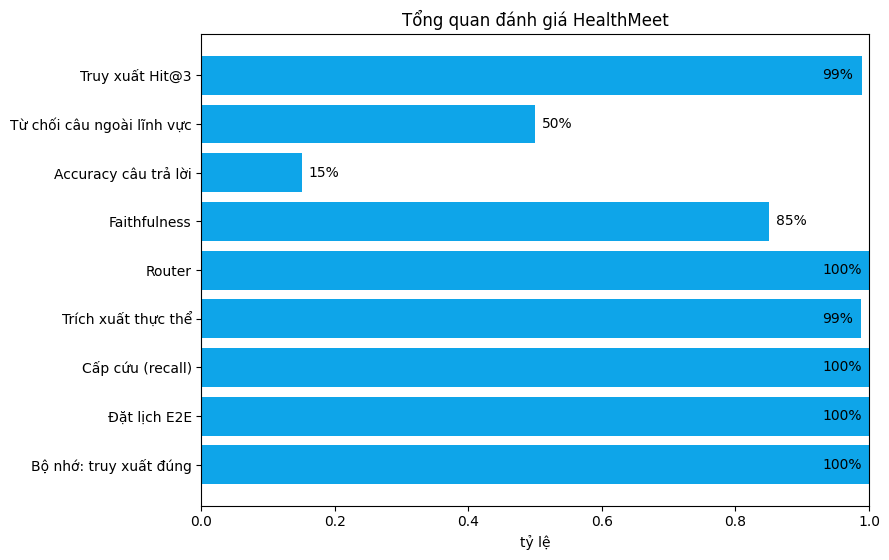

Đã lưu: ['eval_summary.json', 'eval_overview.png', 'answer_eval.csv']


In [25]:
def summarize_all():
    if not EVAL_REPORT:
        print("Chưa có kết quả nào. Hãy chạy các cell đánh giá ở trên."); return
    rows = []
    for part, d in EVAL_REPORT.items():
        for k, v in d.items():
            rows.append({"phần": part, "chỉ số": k, "giá trị": round(v, 3) if isinstance(v, float) else v})
    display(pd.DataFrame(rows))
    json.dump(EVAL_REPORT, open(f"{EVAL_DIR}/eval_summary.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=float)

    # Biểu đồ các chỉ số tỷ lệ chính (0–1)
    pick = {
        "Truy xuất Hit@3": EVAL_REPORT.get("retrieval", {}).get(f"Hit@3 (τ={SIM_TAUS[0]})"),
        "Từ chối câu ngoài lĩnh vực": EVAL_REPORT.get("retrieval", {}).get("OOD rejection"),
        "Accuracy câu trả lời": EVAL_REPORT.get("answers", {}).get("Accuracy (tất cả, điểm ≥ 4)"),
        "Faithfulness": EVAL_REPORT.get("answers", {}).get("Faithfulness (supported = 1, partially = 0.5)"),
        "Router": EVAL_REPORT.get("router", {}).get("accuracy"),
        "Trích xuất thực thể": EVAL_REPORT.get("entities", {}).get("mean"),
        "Cấp cứu (recall)": EVAL_REPORT.get("safety", {}).get("recall"),
        "Đặt lịch E2E": EVAL_REPORT.get("booking_e2e", {}).get("task_success_rate"),
        "Bộ nhớ: truy xuất đúng": EVAL_REPORT.get("memory", {}).get("truy xuất đúng (có nhớ)"),
    }
    pick = {k: v for k, v in pick.items() if v is not None and v == v}
    if pick:
        fig, ax = plt.subplots(figsize=(9, 0.5 * len(pick) + 1.2))
        ax.barh(list(pick)[::-1], list(pick.values())[::-1], color="#0ea5e9")
        ax.set_xlim(0, 1); ax.set_xlabel("tỷ lệ")
        for i, v in enumerate(list(pick.values())[::-1]):
            ax.text(min(v + 0.01, 0.93), i, f"{v:.0%}", va="center")
        ax.set_title("Tổng quan đánh giá HealthMeet"); plt.tight_layout()
        fig.savefig(f"{EVAL_DIR}/eval_overview.png", dpi=130); plt.show()
    print("Đã lưu:", os.listdir(EVAL_DIR))

summarize_all()

## Giao diện chatbot HealthMeet
Giao diện kiểu chatbot thông thường: header thương hiệu, avatar, bong bóng chat, hiệu ứng đang soạn tin, **nút trả lời nhanh** theo ngữ cảnh (đặt lịch, xác nhận, chọn khoa/ngày/giờ…), nút ↻ để bắt đầu cuộc trò chuyện mới. Mỗi tab trình duyệt là **một phiên riêng** (có bộ nhớ hội thoại và trạng thái đặt lịch riêng).

In [26]:
# ============================================================
#  🩺 HealthMeet — giao diện chatbot (Gradio Blocks)
# ============================================================
import gradio as gr, inspect

BOT_NAME = "HealthMeet"

# ---- Đổi tên trợ lý trong prompt (các hàm bên trên đọc biến toàn cục lúc chạy) ----
SYSTEM_QA = SYSTEM_QA.replace("Bạn là trợ lý thông tin y tế tiếng Việt của phòng khám.",
                              f"Bạn là {BOT_NAME}, trợ lý thông tin y tế tiếng Việt của phòng khám.")

def chitchat(msg):
    r = ollama.chat(model=LLM_MODEL, options={"temperature": 0.3, "num_predict": 120, "repeat_penalty": 1.2},
                    messages=[{"role": "system", "content": f"Bạn là {BOT_NAME}, trợ lý sức khỏe của phòng khám. Trả lời xã giao bằng tiếng Việt thân thiện, "
                               "tối đa 2 câu, rồi gợi ý bạn có thể (1) giải đáp thông tin y tế, (2) đặt lịch khám."},
                              {"role": "user", "content": msg}])
    return r["message"]["content"].strip()

# ---- Avatar bot (PNG tròn xanh nhạt + dấu thập y tế) ----
def make_avatar(path):
    try:
        from PIL import Image, ImageDraw
        S_ = 512
        im = Image.new("RGBA", (S_, S_), (0, 0, 0, 0)); d = ImageDraw.Draw(im)
        d.ellipse((0, 0, S_ - 1, S_ - 1), fill="#e0f2fe")
        c, a, b = S_ // 2, 70, 190                     # tâm, nửa bề rộng nét, nửa chiều dài
        d.rounded_rectangle((c - a, c - b, c + a, c + b), 40, fill="#0284c7")
        d.rounded_rectangle((c - b, c - a, c + b, c + a), 40, fill="#0284c7")
        im.resize((128, 128), Image.LANCZOS).save(path)
        return path
    except Exception:
        return None
AVATAR = make_avatar(f"{WORK}/healthmeet_avatar.png")

# ---- Nội dung hội thoại ----
WELCOME = (f"Xin chào! Mình là **{BOT_NAME}** - trợ lý sức khỏe của bạn.\n\n"
           "Mình có thể giải đáp thông tin y tế, gợi ý chuyên khoa và giúp bạn **đặt / hủy lịch khám**.\n\n"
           "*Bạn hãy mô tả triệu chứng đang gặp phải hoặc chọn yêu cầu bên dưới nhé!*")
ERROR_MSG = ("Xin lỗi, hiện tại hệ thống tư vấn đang bận hoặc mất kết nối máy chủ. "
             "Bạn vui lòng thử lại sau giây lát nhé!")
TYPING = '<div class="hm-typing"><span></span><span></span><span></span></div>'

DEFAULT_CHIPS = ["Đặt lịch khám ngay", "Đau dạ dày nên ăn gì?", "Triệu chứng tiểu đường", "Hủy lịch hẹn"]
CHIP_VALUE = {"Có, đặt lịch": "có", "Thay đổi thông tin": "không", "Buổi sáng": "sáng", "Buổi chiều": "chiều"}
N_CHIPS = 6

def _sid(request):
    """Mỗi tab trình duyệt có một session_hash riêng → một phiên hội thoại riêng."""
    return getattr(request, "session_hash", None) or "default"

def chips_for_state(error=False, sid=None):
    """Gợi ý nhanh theo trạng thái hội thoại của đúng phiên (giống nút trả lời nhanh của chatbot thật)."""
    if error:
        return ["Thử lại", "Đặt lịch khám ngay"]
    st_ = get_session(sid)["dst"]
    fl, aw = st_.get("flow"), st_.get("awaiting")
    if fl == "booking":
        if st_.get("stage") == "confirm":
            return ["Có, đặt lịch", "Thay đổi thông tin", "Thoát"]
        if aw == "specialty":
            return SPECIALTIES[:5] + ["Thoát"]
        if aw == "date":
            return ["Hôm nay", "Ngày mai", "Thoát"]
        if aw == "time":
            return ["Buổi sáng", "Buổi chiều", "Thoát"]
        return ["Thoát"]
    if fl == "cancel":
        return ["Thoát"]
    return DEFAULT_CHIPS

def chip_updates(labels, interactive=True):
    labels = labels[:N_CHIPS]
    ups = [gr.update(value=l, visible=True, interactive=interactive) for l in labels]
    return ups + [gr.update(visible=False) for _ in range(N_CHIPS - len(labels))]

def step(msg, history, request: gr.Request = None):
    sid = _sid(request)
    s = get_session(sid)
    msg = (msg or "").strip()
    history = list(history or [])
    msg = CHIP_VALUE.get(msg, msg)
    if msg == "Thử lại":
        msg = s.get("last_user", "")
    if not msg:
        yield (history, "", *chip_updates(chips_for_state(sid=sid)))
        return
    s["last_user"] = msg
    history += [{"role": "user", "content": msg}, {"role": "assistant", "content": TYPING}]
    yield (history, "", *chip_updates(chips_for_state(sid=sid), interactive=False))   # hiện "đang soạn tin…"
    err = False
    try:
        reply = chat_turn(msg, sid)                    # có bộ nhớ theo phiên
    except Exception as e:
        print("[HealthMeet] lỗi:", str(e)[:200]); reply, err = ERROR_MSG, True
    history[-1] = {"role": "assistant", "content": reply}
    yield (history, "", *chip_updates(chips_for_state(err, sid=sid)))

def step_from_chip(label, history, request: gr.Request = None):
    yield from step(label, history, request)

def new_chat(request: gr.Request = None):
    reset_chat(_sid(request))                          # xóa trạng thái đặt lịch + bộ nhớ của phiên này
    return ([{"role": "assistant", "content": WELCOME}], "", *chip_updates(DEFAULT_CHIPS))

# ---- CSS ----
SEND_ICON = ("url(\"data:image/svg+xml;utf8,<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 24 24' fill='white'>"
             "<path d='M2.5 20.5 22 12 2.5 3.5l.01 6.6L16 12 2.51 13.9z'/></svg>\")")
CSS = """
:root, .dark { color-scheme: light; }
.gradio-container { background: linear-gradient(160deg,#e0f2fe 0%,#f0f9ff 55%,#ffffff 100%) !important; max-width: 100% !important; }
footer { display: none !important; }
#hm-app { max-width: 440px; margin: 14px auto !important; background: #fff !important; border-radius: 20px; overflow: hidden;
          border: 1px solid #bae6fd; box-shadow: 0 14px 44px rgba(2,132,199,.22); padding: 0 !important; gap: 0 !important; }
/* header */
#hm-header { background: linear-gradient(135deg,#0369a1,#0ea5e9) !important; padding: 14px 16px !important; gap: 10px !important;
             align-items: center !important; flex-wrap: nowrap !important; border: none !important; }
#hm-brand { display: flex; align-items: center; gap: 12px; }
#hm-brand .logo { width: 42px; height: 42px; border-radius: 50%; background: #e0f2fe; display: flex; align-items: center; justify-content: center; }
#hm-brand .name { color: #fff; font-weight: 700; font-size: 18px; line-height: 1.2; }
#hm-brand .status { color: #e0f2fe; font-size: 12.5px; }
#hm-brand .dot { display: inline-block; width: 8px; height: 8px; border-radius: 50%; background: #4ade80; margin-right: 6px; }
#hm-reset { flex: 0 0 38px !important; min-width: 38px !important; width: 38px !important; height: 38px; padding: 0 !important; border-radius: 50% !important;
            background: rgba(255,255,255,.18) !important; color: #fff !important; border: none !important; font-size: 18px !important; }
#hm-reset:hover { background: rgba(255,255,255,.32) !important; }
/* khung chat */
#hm-chat { border: none !important; box-shadow: none !important; }
/* 1. nền sáng cho mọi khung chứa (kể cả khi Gradio ở chế độ tối) */
#hm-app #hm-chat, #hm-app #hm-chat > div, #hm-app #hm-chat .wrapper, #hm-app #hm-chat .bubble-wrap,
#hm-app #hm-chat .message-wrap, #hm-app #hm-chat .message-row, #hm-app #hm-chat .flex-wrap,
#hm-app #hm-chat .chatbot, #hm-app #hm-chat .panel-wrap { background: #f8fbfe !important; }
/* 2. bong bóng */
#hm-chat [data-testid="user"], #hm-chat .message.user {
    background: #0284c7 !important; border: none !important; border-radius: 18px 18px 4px 18px !important; }
#hm-chat [data-testid="bot"], #hm-chat .message.bot {
    background: #fff !important; border: 1px solid #e0f2fe !important;
    border-radius: 18px 18px 18px 4px !important; box-shadow: 0 1px 4px rgba(2,132,199,.10) !important; }
/* 3. lớp lồng bên trong: bỏ viền/nền để chỉ còn 1 bong bóng */
#hm-chat .message [data-testid="bot"], #hm-chat .message [data-testid="user"],
#hm-chat [data-testid="bot"] .message.bot, #hm-chat [data-testid="user"] .message.user {
    background: transparent !important; border: none !important; box-shadow: none !important; border-radius: 0 !important; }
/* 4. màu chữ: bot = đen, user = trắng */
#hm-chat [data-testid="bot"], #hm-chat .message.bot,
#hm-chat [data-testid="bot"] *, #hm-chat .message.bot * { color: #0f172a !important; opacity: 1 !important; }
#hm-chat [data-testid="user"], #hm-chat .message.user,
#hm-chat [data-testid="user"] *, #hm-chat .message.user * { color: #ffffff !important; opacity: 1 !important; }
#hm-chat .message { font-size: 15px; line-height: 1.55; }
#hm-chat .avatar-image { border-radius: 50% !important; background: #e0f2fe; }
/* 5. ẩn nút chia sẻ / xóa / sao chép của Gradio */
#hm-chat .icon-button-wrapper, #hm-chat .message-buttons, #hm-chat .message-buttons-bubble,
#hm-chat button.copy, #hm-chat button[aria-label="Copy message"], #hm-chat button[aria-label="Clear"],
#hm-chat button[aria-label="Share"], #hm-chat button[aria-label="Copy conversation"] { display: none !important; }
#hm-chat .hm-typing span { background: #7dd3fc !important; }
/* ẩn khung đen "đang xử lý" + đồng hồ đếm giây + viền cam của Gradio */
#hm-app .wrap.default, #hm-app .wrap.center, #hm-app .wrap.minimal, #hm-app .translucent, #hm-app .timer,
#hm-app .progress-text, #hm-app .meta-text, #hm-app .meta-text-center, #hm-app .eta-bar,
#hm-app .status-tracker, #hm-app .loading, #hm-app .progress-level { display: none !important; }
#hm-app .generating, #hm-app .pending, #hm-app .block.generating, #hm-app .block.pending {
    border: none !important; outline: none !important; box-shadow: none !important; animation: none !important; }
/* typing */
.hm-typing { display: flex; gap: 5px; padding: 6px 2px; }
.hm-typing span { width: 8px; height: 8px; border-radius: 50%; background: #7dd3fc; animation: hm-bounce 1.2s infinite ease-in-out; }
.hm-typing span:nth-child(2) { animation-delay: .15s; } .hm-typing span:nth-child(3) { animation-delay: .3s; }
@keyframes hm-bounce { 0%,60%,100% { transform: translateY(0); opacity: .5; } 30% { transform: translateY(-6px); opacity: 1; } }
/* nút trả lời nhanh */
#hm-chips { background: #f8fbfe !important; padding: 6px 14px 10px !important; gap: 8px !important; flex-wrap: wrap !important; border: none !important; }
.hm-chip { flex: 0 0 auto !important; width: auto !important; min-width: 0 !important; background: #fff !important; color: #0369a1 !important;
           border: 1px solid #bae6fd !important; border-radius: 999px !important; font-weight: 600 !important; font-size: 13.5px !important;
           padding: 7px 14px !important; box-shadow: none !important; }
.hm-chip:hover:not([disabled]) { background: #e0f2fe !important; border-color: #38bdf8 !important; }
/* ô nhập */
#hm-input-row { padding: 10px 14px 6px !important; gap: 10px !important; align-items: center !important; flex-wrap: nowrap !important;
                border-top: 1px solid #e2e8f0 !important; background: #fff !important; }
#hm-input, #hm-input > label, #hm-input .container { background: transparent !important; border: none !important; box-shadow: none !important; padding: 0 !important; }
#hm-input textarea { border-radius: 999px !important; border: 1px solid #cbd5e1 !important; background: #fff !important; color: #0f172a !important;
                     padding: 12px 18px !important; font-size: 15px !important; box-shadow: none !important; }
#hm-input textarea:focus { border-color: #0284c7 !important; box-shadow: 0 0 0 3px rgba(2,132,199,.15) !important; }
#hm-send { flex: 0 0 46px !important; min-width: 46px !important; width: 46px !important; height: 46px; border-radius: 50% !important; padding: 0 !important;
           font-size: 0 !important; border: none !important; background: #0284c7 __SEND__ center / 22px no-repeat !important; }
#hm-send:hover { background-color: #0369a1 !important; }
#hm-note { text-align: center; font-size: 11.5px; color: #94a3b8; padding: 2px 16px 12px; background: #fff; }
""".replace("__SEND__", SEND_ICON)

LOGO_SVG = ("<svg width='26' height='26' viewBox='0 0 24 24'><path fill='#0284c7' "
            "d='M9 2h6a1 1 0 0 1 1 1v5h5a1 1 0 0 1 1 1v6a1 1 0 0 1-1 1h-5v5a1 1 0 0 1-1 1H9a1 1 0 0 1-1-1v-5H3a1 1 0 0 1-1-1V9a1 1 0 0 1 1-1h5V3a1 1 0 0 1 1-1z'/></svg>")
HEADER_HTML = (f"<div id='hm-brand'><div class='logo'>{LOGO_SVG}</div><div><div class='name'>{BOT_NAME}</div>"
               "<div class='status'><span class='dot'></span>Đang trực tuyến · Tư vấn &amp; đặt lịch khám</div></div></div>")
NOTE_HTML = ("<div id='hm-note'>Thông tin chỉ mang tính tham khảo, không thay thế bác sĩ.<br>"
             "Trường hợp khẩn cấp hãy gọi <b>115</b>.</div>")

def build(cls, **kw):
    """Tạo component, bỏ qua tham số mà phiên bản Gradio đang dùng không hỗ trợ."""
    ps = inspect.signature(cls.__init__).parameters
    return cls(**{k: v for k, v in kw.items() if k in ps})

blocks_kw = dict(title=f"{BOT_NAME} — Trợ lý sức khỏe")
launch_kw = dict(share=True, debug=False)
if "css" in inspect.signature(gr.Blocks.__init__).parameters:
    blocks_kw["css"] = CSS
else:                                   # Gradio ≥ 6: css truyền vào launch()
    launch_kw["css"] = CSS

with gr.Blocks(**blocks_kw) as demo:
    with gr.Column(elem_id="hm-app"):
        with gr.Row(elem_id="hm-header"):
            gr.HTML(HEADER_HTML)
            btn_reset = gr.Button("↻", elem_id="hm-reset")
        chat = build(gr.Chatbot, value=[{"role": "assistant", "content": WELCOME}], type="messages", elem_id="hm-chat",
                     height=470, show_label=False, container=False, avatar_images=(None, AVATAR),
                     bubble_full_width=False, show_copy_button=False, show_share_button=False,
                     sanitize_html=True, label=BOT_NAME)
        with gr.Row(elem_id="hm-chips"):
            chip_btns = [gr.Button(DEFAULT_CHIPS[i] if i < len(DEFAULT_CHIPS) else "", elem_classes="hm-chip",
                                   visible=i < len(DEFAULT_CHIPS)) for i in range(N_CHIPS)]
        with gr.Row(elem_id="hm-input-row"):
            box = build(gr.Textbox, placeholder="Mô tả triệu chứng hoặc hỏi đặt lịch...", show_label=False, container=False,
                        lines=1, max_lines=4, scale=8, elem_id="hm-input", autofocus=True)
            btn_send = gr.Button("Gửi", elem_id="hm-send", scale=1)
        gr.HTML(NOTE_HTML)

    outs = [chat, box] + chip_btns
    box.submit(step, [box, chat], outs)
    btn_send.click(step, [box, chat], outs)
    for b in chip_btns:
        b.click(step_from_chip, [b, chat], outs)
    btn_reset.click(new_chat, None, outs)

reset_chat()
demo.queue().launch(**launch_kw)


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://50568f70fe8ba1a7b9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
